# Cavity pulses with a trip label

One row per cavity pulse: `cavity`, `value_1` … `value_n` (field amplitude, bin means over the whole record), `label`.

- `label = 0`: every pulse of the DD captures (nominal operation, taken on demand).
- `label = 1`: the last `TRIP_PULSES` pulses of each PM capture (taken when the beam trips; rank 0 is the pulse of the trip).

The other PM pulses are left out: they come before the trip, so they are neither clearly nominal nor the trip.

Source: `cavity_pulses.parquet` written by `../notebooks/ess_dd/ess_dd_features.py` for the DD and the PM captures.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOKS = Path("../notebooks")
OUT = Path("cavity_pulses_labeled.parquet")
TRIP_PULSES = 1
COLUMNS = ["cavity", "field_amp_bins", "cycle_rank_from_last"]

In [3]:
dd = pd.read_parquet(NOTEBOOKS / "ess_dd" / "cavity_pulses.parquet", columns=COLUMNS).assign(label=0)
pm = pd.read_parquet(NOTEBOOKS / "ess_pm" / "cavity_pulses.parquet", columns=COLUMNS)
pm = pm[pm["cycle_rank_from_last"] < TRIP_PULSES].assign(label=1)
pulses = pd.concat([dd, pm], ignore_index=True)

values = np.stack(pulses["field_amp_bins"].to_numpy())
dataset = pd.concat([
    pulses[["cavity"]],
    pd.DataFrame(values, columns=[f"value_{i + 1}" for i in range(values.shape[1])]),
    pulses[["label"]],
], axis=1)
dataset.to_parquet(OUT, index=False)
print(OUT.resolve(), dataset.shape)
dataset["label"].value_counts()

/workspace/lustre/work/pdl18409/shared/data/anomaly-detection/teams/the-outliers/cavity_dataset/cavity_pulses_labeled.parquet (40223, 66)


label
0    35414
1     4809
Name: count, dtype: int64

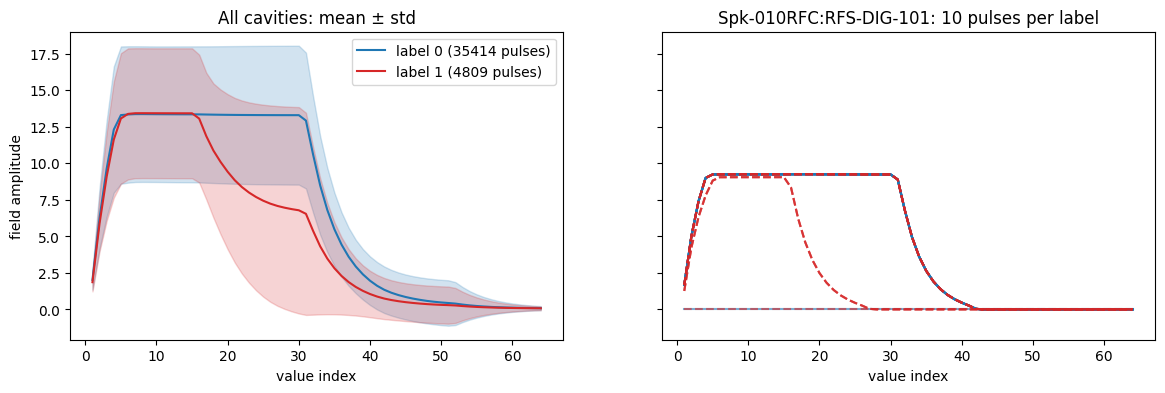

In [4]:
value_columns = [c for c in dataset.columns if c.startswith("value_")]
cavity = dataset.loc[dataset["label"] == 1, "cavity"].value_counts().index[0]
one = dataset[dataset["cavity"] == cavity]

fig, (mean_ax, sample_ax) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for label, color, style in [(0, "tab:blue", "-"), (1, "tab:red", "--")]:
    rows = dataset.loc[dataset["label"] == label, value_columns].to_numpy()
    mean, std = rows.mean(axis=0), rows.std(axis=0)
    x = np.arange(1, len(value_columns) + 1)
    mean_ax.plot(x, mean, color=color, label=f"label {label} ({len(rows)} pulses)")
    mean_ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.2)
    for row in one.loc[one["label"] == label, value_columns].sample(10, random_state=0).to_numpy():
        sample_ax.plot(x, row, color=color, linestyle=style, alpha=0.6)
mean_ax.set(title="All cavities: mean ± std", xlabel="value index", ylabel="field amplitude")
mean_ax.legend()
sample_ax.set(title=f"{cavity}: 10 pulses per label", xlabel="value index")
plt.show()

In [5]:
value_columns = [c for c in dataset.columns if c.startswith("value_")]

dd_only = dataset[dataset["label"] == 0].copy()

dd_only["mean"] = dd_only[value_columns].mean(axis=1)
dd_only["std"] = dd_only[value_columns].std(axis=1)
dd_only["min"] = dd_only[value_columns].min(axis=1)
dd_only["max"] = dd_only[value_columns].max(axis=1)
dd_only["range"] = dd_only["max"] - dd_only["min"]

dd_stats = dd_only[
    ["cavity", "mean", "std", "min", "max", "range"]
]

display(dd_stats.head(20))

,cavity,mean,std,min,max,range
0,HBL-010RFC:RFS-DIG-101,5.557890,7.738515,0.215462,19.787766,19.572304
1,HBL-010RFC:RFS-DIG-201,5.032678,7.016352,0.120836,17.863754,17.742918
2,HBL-010RFC:RFS-DIG-401,5.496892,7.714774,0.000000,19.547852,19.547852
3,HBL-010RFC:RFS-DIG-301,4.915654,6.995852,0.000000,17.684509,17.684509
4,HBL-010RFC:RFS-DIG-401,5.496830,7.714846,0.000000,19.547930,19.547930
5,HBL-010RFC:RFS-DIG-301,4.916027,6.995636,0.000000,17.684490,17.684490
6,HBL-010RFC:RFS-DIG-101,5.556869,7.738068,0.215449,19.787525,19.572077
7,HBL-010RFC:RFS-DIG-201,5.031763,7.016291,0.120815,17.863541,17.742725
8,HBL-010RFC:RFS-DIG-401,5.500826,7.714758,0.000000,19.549051,19.549051
9,HBL-010RFC:RFS-DIG-201,5.031909,7.016373,0.120804,17.863676,17.742872


In [6]:
cavity_name = "HBL-010RFC:RFS-DIG-101"

cavity_df = dd_stats[dd_stats["cavity"] == cavity_name].reset_index(drop=True)

display(cavity_df)

,cavity,mean,std,min,max,range
0,HBL-010RFC:RFS-DIG-101,5.557890,7.738515,0.215462,19.787766,19.572304
1,HBL-010RFC:RFS-DIG-101,5.556869,7.738068,0.215449,19.787525,19.572077
2,HBL-010RFC:RFS-DIG-101,5.556579,7.737775,0.215427,19.787056,19.571629
3,HBL-010RFC:RFS-DIG-101,5.558135,7.738444,0.215429,19.788383,19.572954
4,HBL-010RFC:RFS-DIG-101,5.557323,7.738052,0.215436,19.787315,19.571878
...,...,...,...,...,...,...
432,HBL-010RFC:RFS-DIG-101,10.387723,9.051884,0.215503,19.952892,19.737389
433,HBL-010RFC:RFS-DIG-101,10.389402,9.050953,0.215526,19.952957,19.737431
434,HBL-010RFC:RFS-DIG-101,10.388836,9.051300,0.215499,19.952944,19.737446
435,HBL-010RFC:RFS-DIG-101,10.391621,9.049738,0.215559,19.952923,19.737364


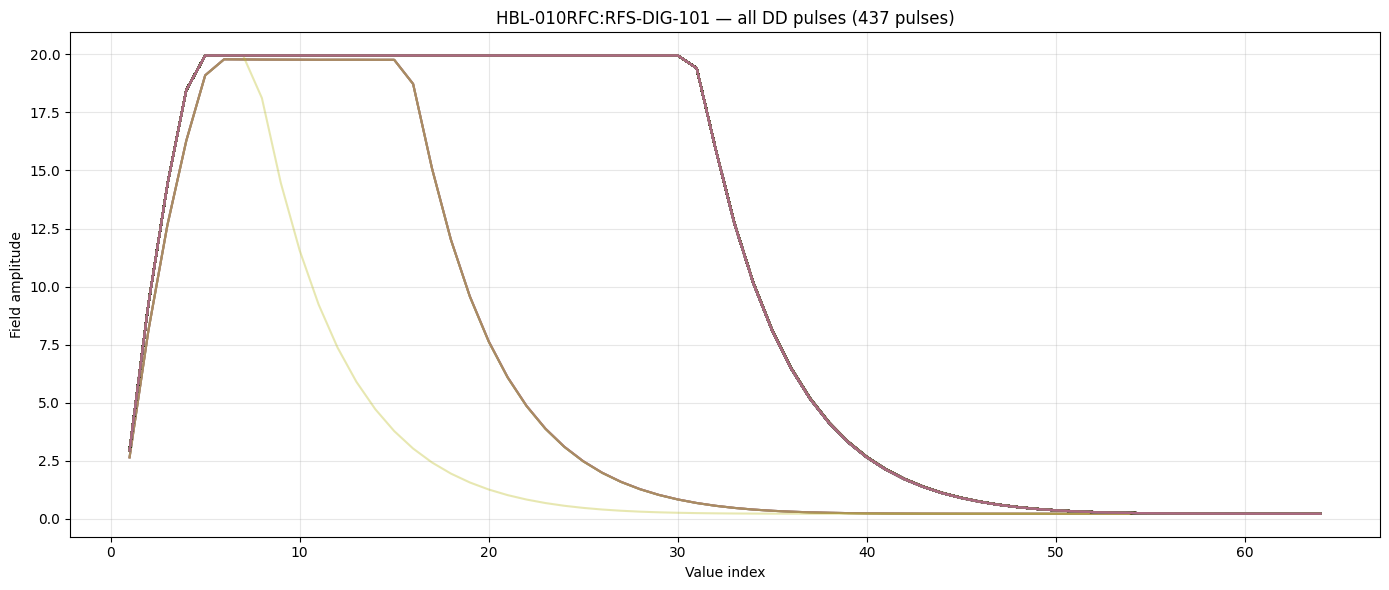

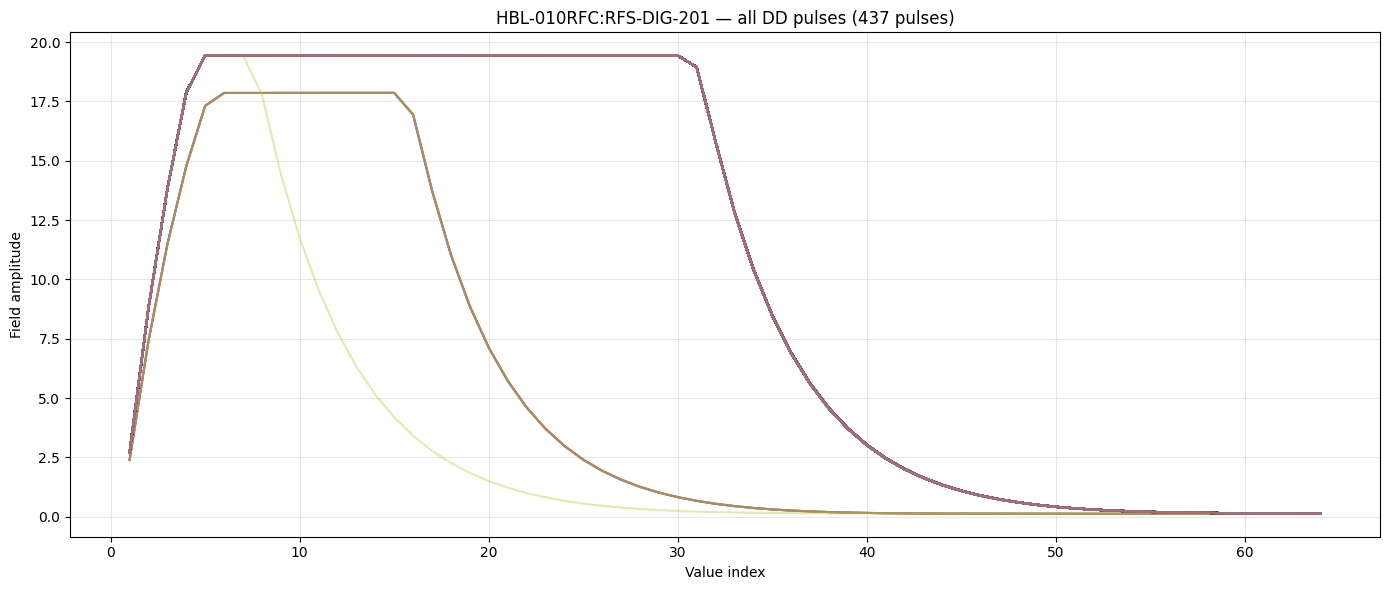

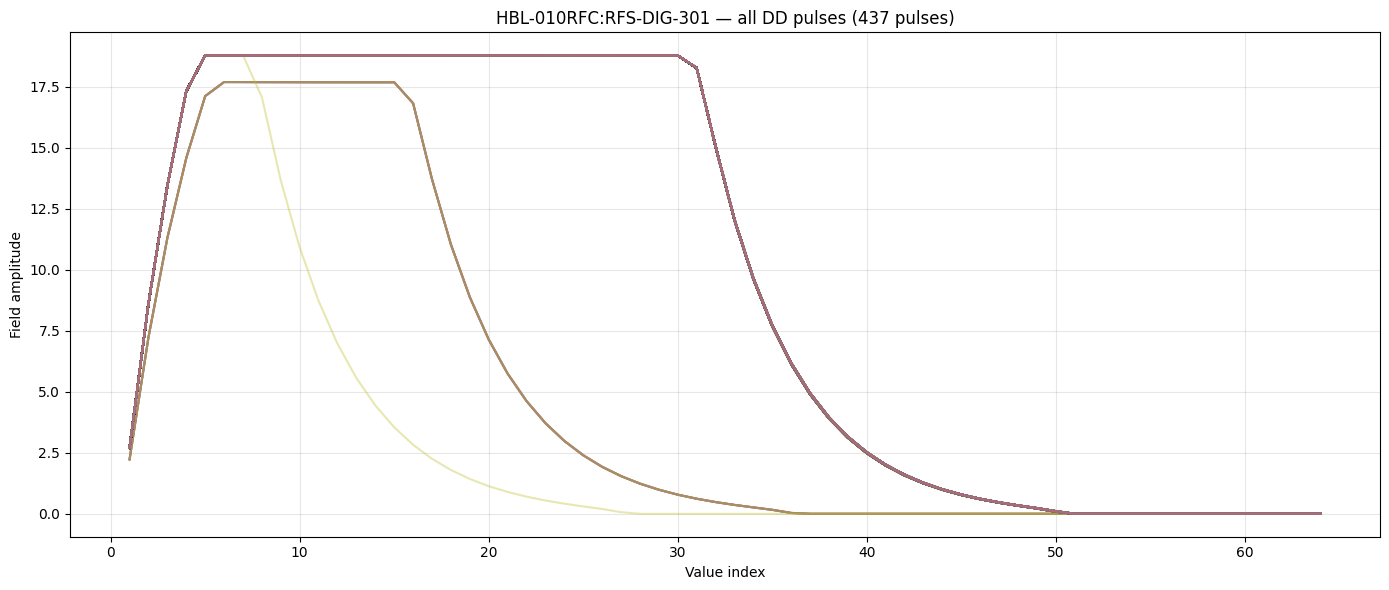

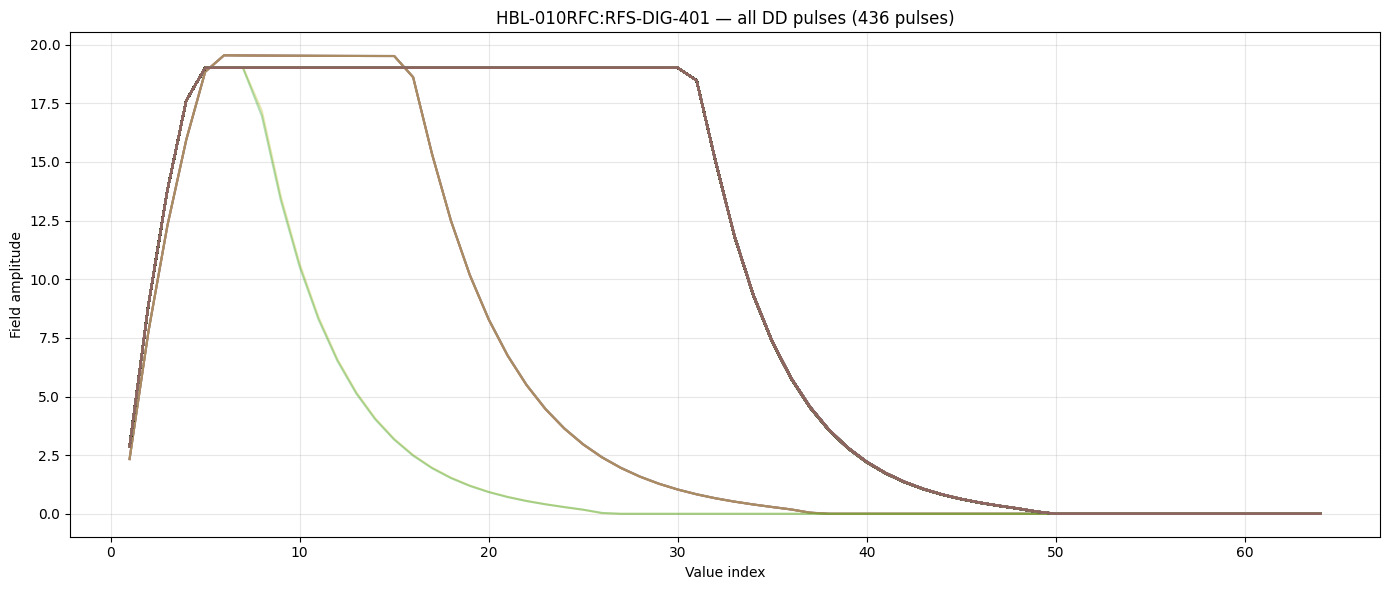

In [40]:
cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

x = np.arange(1, len(value_columns) + 1)

for cavity_name in cavity_names:

    cavity_df = dd_only[
        dd_only["cavity"] == cavity_name
    ].reset_index(drop=True)

    plt.figure(figsize=(14, 6))

    for i, row in cavity_df.iterrows():
        y = row[value_columns].to_numpy(dtype=float)

        plt.plot(
            x,
            y,
            alpha=0.35
        )

    plt.xlabel("Value index")
    plt.ylabel("Field amplitude")
    plt.title(
        f"{cavity_name} — all DD pulses "
        f"({len(cavity_df)} pulses)"
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

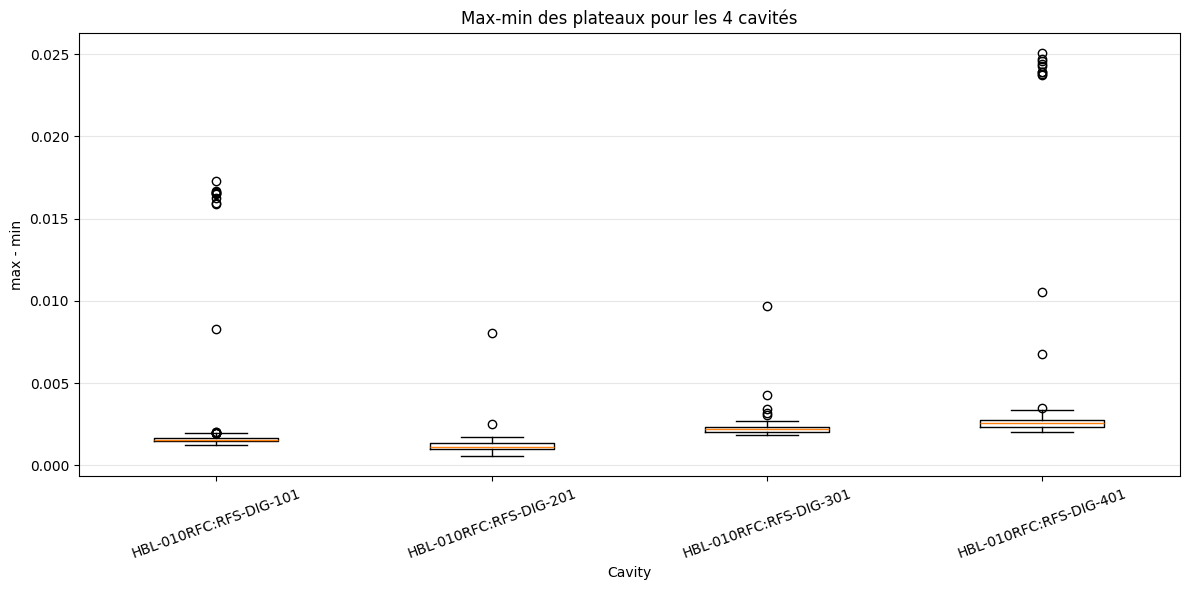

In [57]:
plt.figure(figsize=(12, 6))

data = [
    plateau_stats_all.loc[
        plateau_stats_all["cavity"] == cavity,
        "max_minus_min"
    ].dropna()
    for cavity in cavity_names
]

plt.boxplot(
    data,
    tick_labels=cavity_names
)

plt.xlabel("Cavity")
plt.ylabel("max - min")
plt.title("Max-min des plateaux pour les 4 cavités")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

all_plateau_stats = []

for cavity_name in cavity_names:

    cavity_df = dd_only[
        dd_only["cavity"] == cavity_name
    ].reset_index(drop=True)

    results = []

    for i, row in cavity_df.iterrows():

        y = row[value_columns].to_numpy(dtype=float)

        plateau = get_flat_plateau(
            y,
            slope_threshold=0.1,
            amp_min=18,
            amp_max=24
        )

        if plateau is not None:
            start, end = plateau
            flat = y[start:end]

            results.append({
                "cavity": cavity_name,
                "pulse": i + 1,
                "start_x": start + 1,
                "end_x": end,
                "n_points": len(flat),
                "min": flat.min(),
                "max": flat.max(),
                "max_minus_min": flat.max() - flat.min(),
                "mean": flat.mean(),
                "std": flat.std()
            })

    cavity_stats = pd.DataFrame(results)
    all_plateau_stats.append(cavity_stats)

plateau_stats_all = pd.concat(
    all_plateau_stats,
    ignore_index=True
)

display(plateau_stats_all.head())

,cavity,pulse,start_x,end_x,n_points,min,max,max_minus_min,mean,std
0,HBL-010RFC:RFS-DIG-101,1,7,15,9,19.766281,19.782183,0.015902,19.770797,0.004888
1,HBL-010RFC:RFS-DIG-101,2,7,15,9,19.765884,19.782475,0.016590,19.770803,0.005173
2,HBL-010RFC:RFS-DIG-101,3,7,15,9,19.765106,19.781794,0.016687,19.770058,0.005242
3,HBL-010RFC:RFS-DIG-101,4,7,15,9,19.765709,19.783009,0.017300,19.770812,0.005328
4,HBL-010RFC:RFS-DIG-101,5,7,15,9,19.766048,19.782009,0.015961,19.770656,0.005030


In [44]:
outliers_all = []

for cavity_name in cavity_names:

    df_cav = plateau_stats_all[
        plateau_stats_all["cavity"] == cavity_name
    ].copy()

    q1 = df_cav["max_minus_min"].quantile(0.25)
    q3 = df_cav["max_minus_min"].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df_cav[
        (df_cav["max_minus_min"] < lower_bound) |
        (df_cav["max_minus_min"] > upper_bound)
    ].copy()

    outliers_all.append(outliers)

    print("\n", cavity_name)
    print("Outlier pulse indices:")
    print(outliers["pulse"].tolist())


 HBL-010RFC:RFS-DIG-101
Outlier pulse indices:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 221, 224, 228, 229, 240, 241, 258, 261, 268]

 HBL-010RFC:RFS-DIG-201
Outlier pulse indices:
[229, 324]

 HBL-010RFC:RFS-DIG-301
Outlier pulse indices:
[229, 324, 325, 326, 327]

 HBL-010RFC:RFS-DIG-401
Outlier pulse indices:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 229, 293, 323]


In [46]:
cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

label1 = dataset[dataset["label"] == 1].copy()

In [47]:
all_plateau_stats_label1 = []

for cavity_name in cavity_names:

    cavity_df = label1[
        label1["cavity"] == cavity_name
    ].reset_index(drop=True)

    results = []

    for i, row in cavity_df.iterrows():

        y = row[value_columns].to_numpy(dtype=float)

        plateau = get_flat_plateau(
            y,
            slope_threshold=0.1,
            amp_min=18,
            amp_max=24
        )

        if plateau is not None:
            start, end = plateau
            flat = y[start:end]

            results.append({
                "cavity": cavity_name,
                "pulse": i + 1,
                "start_x": start + 1,
                "end_x": end,
                "n_points": len(flat),
                "min": flat.min(),
                "max": flat.max(),
                "max_minus_min": flat.max() - flat.min(),
                "mean": flat.mean(),
                "std": flat.std()
            })

    cavity_stats = pd.DataFrame(results)
    all_plateau_stats_label1.append(cavity_stats)

plateau_stats_label1 = pd.concat(
    all_plateau_stats_label1,
    ignore_index=True
)

display(plateau_stats_label1.head())

,cavity,pulse,start_x,end_x,n_points,min,max,max_minus_min,mean,std
0,HBL-010RFC:RFS-DIG-101,1,7,15,9,19.765759,19.782373,0.016615,19.770849,0.004990
1,HBL-010RFC:RFS-DIG-101,2,7,15,9,19.765154,19.782450,0.017296,19.770592,0.005266
2,HBL-010RFC:RFS-DIG-101,3,7,15,9,19.766144,19.782314,0.016171,19.770987,0.004955
3,HBL-010RFC:RFS-DIG-101,4,7,15,9,19.764069,19.780935,0.016867,19.769272,0.005270
4,HBL-010RFC:RFS-DIG-101,5,7,15,9,19.765430,19.782606,0.017176,19.770897,0.005183


/tmp/ipykernel_1736245/367998495.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


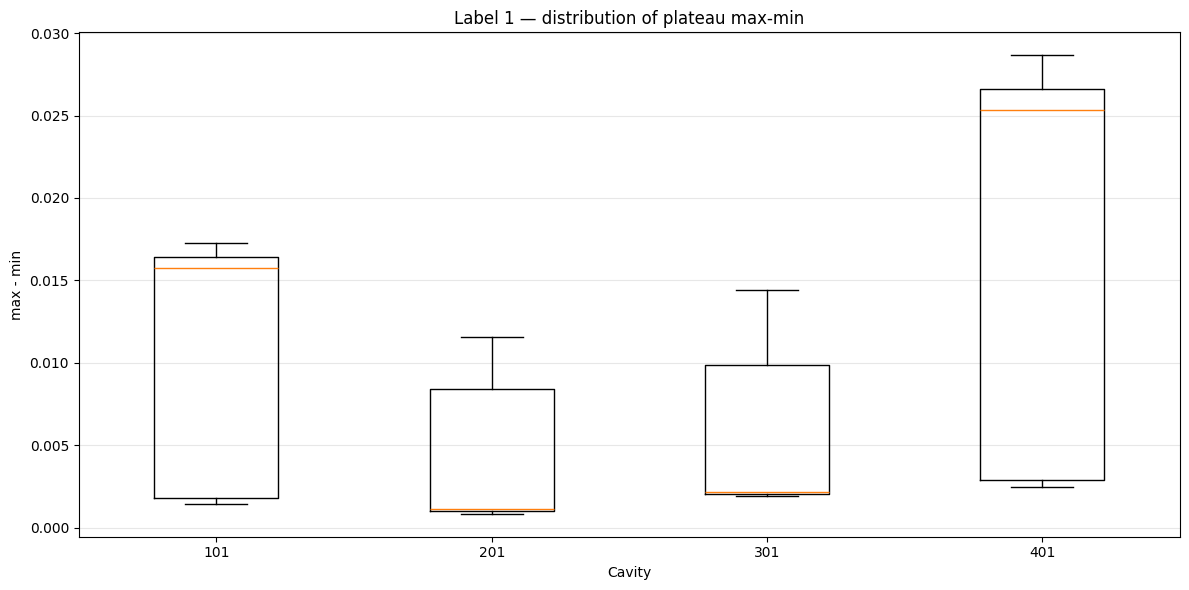

In [48]:
plt.figure(figsize=(12, 6))

data = [
    plateau_stats_label1.loc[
        plateau_stats_label1["cavity"] == cavity,
        "max_minus_min"
    ].dropna()
    for cavity in cavity_names
]

plt.boxplot(
    data,
    labels=["101", "201", "301", "401"]
)

plt.xlabel("Cavity")
plt.ylabel("max - min")
plt.title("Label 1 — distribution of plateau max-min")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
WINDOW_SIZE = 6

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

all_window_stats = []

for cavity_name in cavity_names:

    cavity_df = dd_only[
        dd_only["cavity"] == cavity_name
    ].reset_index(drop=True)

    results = []

    for i, row in cavity_df.iterrows():

        y = row[value_columns].to_numpy(dtype=float)

        plateau = get_flat_plateau(
            y,
            slope_threshold=0.1,
            amp_min=18,
            amp_max=24
        )

        if plateau is not None:

            start, end = plateau
            flat = y[start:end]

            window_ranges = []

            for j in range(
                0,
                len(flat) - WINDOW_SIZE + 1,
                WINDOW_SIZE
            ):
                window = flat[j:j + WINDOW_SIZE]

                window_ranges.append(
                    window.max() - window.min()
                )

            if len(window_ranges) > 0:

                results.append({
                    "cavity": cavity_name,
                    "pulse": i + 1,
                    "mean_window_range": np.mean(window_ranges),
                    "std_window_range": np.std(window_ranges),
                    "max_window_range": np.max(window_ranges),
                    "n_windows": len(window_ranges)
                })

    cavity_window_stats = pd.DataFrame(results)
    all_window_stats.append(cavity_window_stats)

window_stats_all = pd.concat(
    all_window_stats,
    ignore_index=True
)

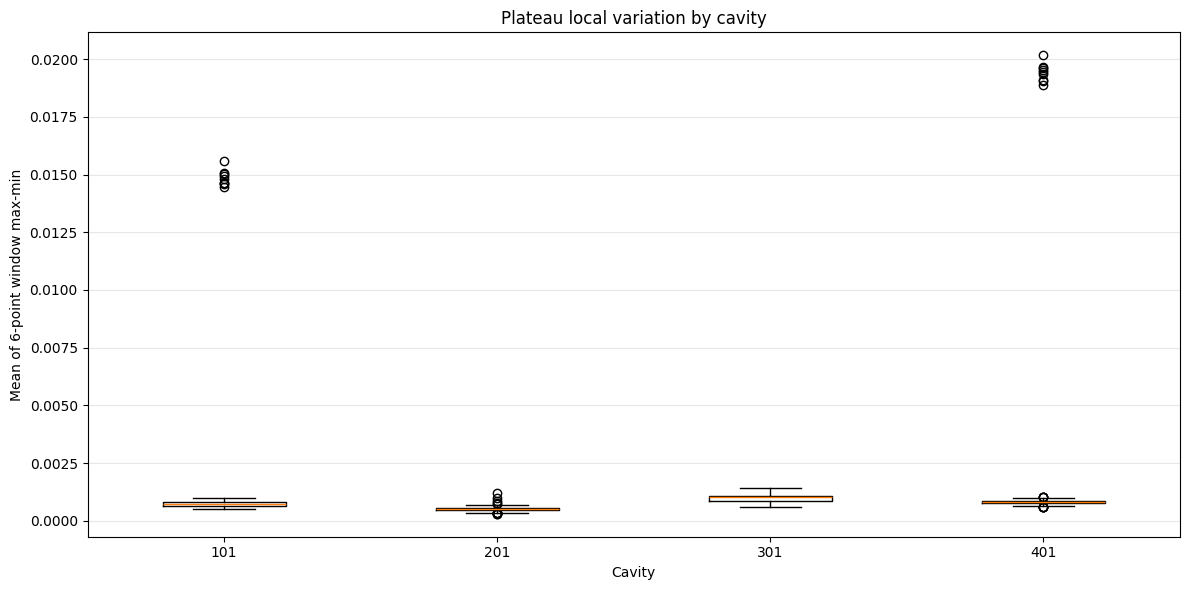

In [56]:
data = [
    window_stats_all.loc[
        window_stats_all["cavity"] == cavity,
        "mean_window_range"
    ].dropna()
    for cavity in cavity_names
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    data,
    tick_labels=["101", "201", "301", "401"]
)

plt.xlabel("Cavity")
plt.ylabel("Mean of 6-point window max-min")
plt.title("Plateau local variation by cavity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
WINDOW_SIZE = 6

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

label1 = dataset[dataset["label"] == 1].copy()

all_window_stats_label1 = []

for cavity_name in cavity_names:

    cavity_df = label1[
        label1["cavity"] == cavity_name
    ].reset_index(drop=True)

    results = []

    for i, row in cavity_df.iterrows():

        y = row[value_columns].to_numpy(dtype=float)

        plateau = get_flat_plateau(
            y,
            slope_threshold=0.1,
            amp_min=18,
            amp_max=24
        )

        if plateau is not None:

            start, end = plateau
            flat = y[start:end]

            window_ranges = []

            for j in range(
                0,
                len(flat) - WINDOW_SIZE + 1,
                WINDOW_SIZE
            ):
                window = flat[j:j + WINDOW_SIZE]

                window_ranges.append(
                    window.max() - window.min()
                )

            if len(window_ranges) > 0:

                results.append({
                    "cavity": cavity_name,
                    "pulse": i + 1,
                    "mean_window_range": np.mean(window_ranges),
                    "std_window_range": np.std(window_ranges),
                    "max_window_range": np.max(window_ranges),
                    "n_windows": len(window_ranges)
                })

    cavity_window_stats = pd.DataFrame(results)
    all_window_stats_label1.append(cavity_window_stats)

window_stats_label1 = pd.concat(
    all_window_stats_label1,
    ignore_index=True
)

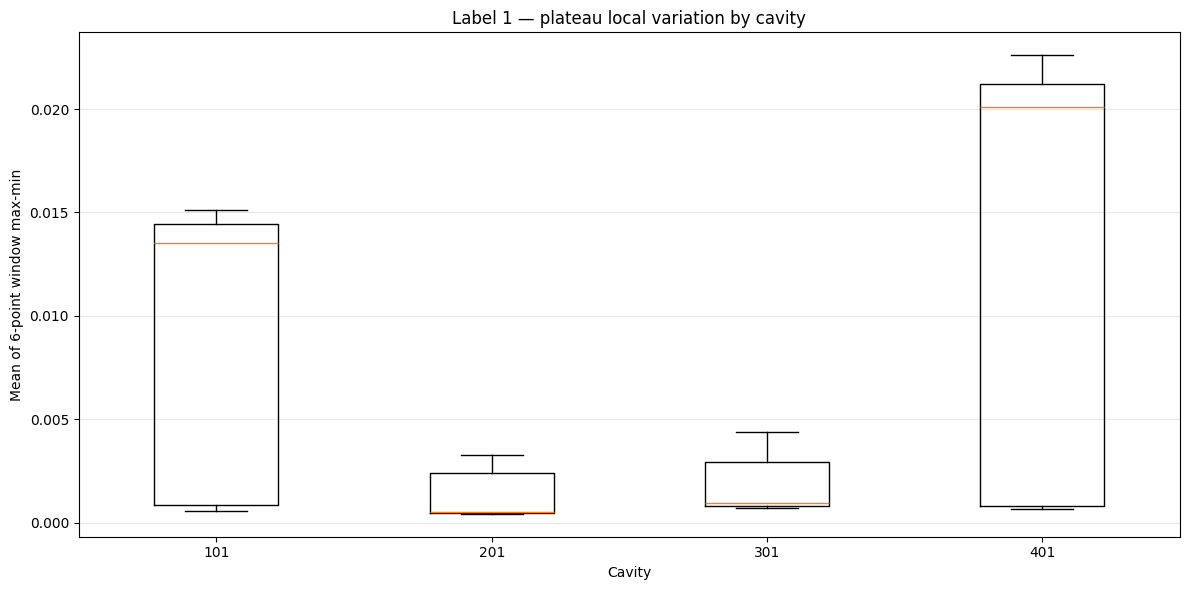

In [59]:
data = [
    window_stats_label1.loc[
        window_stats_label1["cavity"] == cavity,
        "mean_window_range"
    ].dropna()
    for cavity in cavity_names
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    data,
    tick_labels=["101", "201", "301", "401"]
)

plt.xlabel("Cavity")
plt.ylabel("Mean of 6-point window max-min")
plt.title("Label 1 — plateau local variation by cavity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
comparison_data = []
positions = []
labels = []

pos = 1

for cavity in cavity_names:

    # label 0
    d0 = window_stats_all.loc[
        window_stats_all["cavity"] == cavity,
        "mean_window_range"
    ].dropna()

    # label 1
    d1 = window_stats_label1.loc[
        window_stats_label1["cavity"] == cavity,
        "mean_window_range"
    ].dropna()

    comparison_data.extend([d0, d1])
    positions.extend([pos, pos + 0.35])

    pos += 1.3

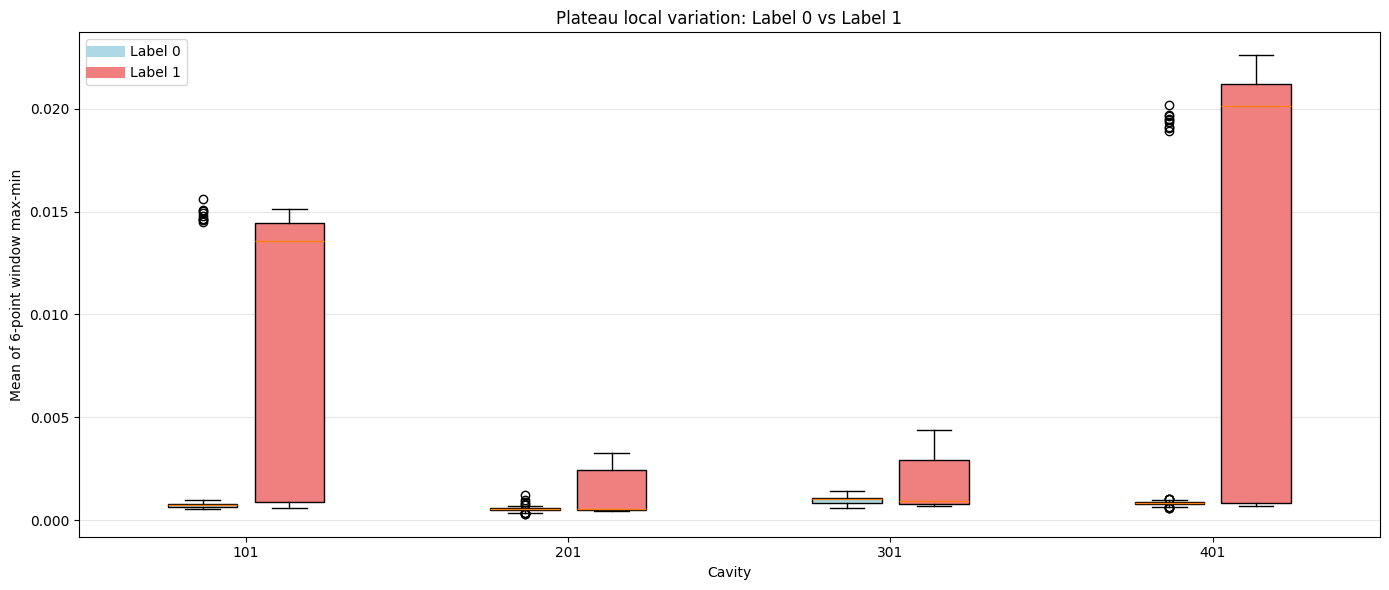

In [61]:
plt.figure(figsize=(14, 6))

bp = plt.boxplot(
    comparison_data,
    positions=positions,
    widths=0.28,
    patch_artist=True
)

# alternate colors label 0 / label 1
for i, box in enumerate(bp["boxes"]):
    if i % 2 == 0:
        box.set_facecolor("lightblue")   # label 0
    else:
        box.set_facecolor("lightcoral")  # label 1

centers = [
    (positions[i] + positions[i + 1]) / 2
    for i in range(0, len(positions), 2)
]

plt.xticks(
    centers,
    ["101", "201", "301", "401"]
)

plt.xlabel("Cavity")
plt.ylabel("Mean of 6-point window max-min")
plt.title("Plateau local variation: Label 0 vs Label 1")

plt.plot([], [], color="lightblue", linewidth=8, label="Label 0")
plt.plot([], [], color="lightcoral", linewidth=8, label="Label 1")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
for cavity in cavity_names:

    d0 = window_stats_all.loc[
        window_stats_all["cavity"] == cavity,
        "mean_window_range"
    ]

    d1 = window_stats_label1.loc[
        window_stats_label1["cavity"] == cavity,
        "mean_window_range"
    ]

    print("\n", cavity)

    print(
        "Label 0:",
        "n =", len(d0),
        "median =", d0.median(),
        "mean =", d0.mean()
    )

    print(
        "Label 1:",
        "n =", len(d1),
        "median =", d1.median(),
        "mean =", d1.mean()
    )


 HBL-010RFC:RFS-DIG-101
Label 0: n = 436 median = 0.0007169246673583984 mean = 0.0010078095514839942
Label 1: n = 59 median = 0.013545989990234375 mean = 0.00817351422067416

 HBL-010RFC:RFS-DIG-201
Label 0: n = 427 median = 0.000514984130859375 mean = 0.0005244170195604096
Label 1: n = 28 median = 0.0005230903625488281 mean = 0.001223581177847726

 HBL-010RFC:RFS-DIG-301
Label 0: n = 427 median = 0.0010151863098144531 mean = 0.0009625689486429898
Label 1: n = 28 median = 0.0009388923645019531 mean = 0.0017821788787841797

 HBL-010RFC:RFS-DIG-401
Label 0: n = 434 median = 0.0008106231689453125 mean = 0.0011927279459166638
Label 1: n = 57 median = 0.020107269287109375 mean = 0.012176522037439179


In [63]:
upper_outliers_dd = []

for cavity_name in cavity_names:

    df_cav = window_stats_all[
        window_stats_all["cavity"] == cavity_name
    ].copy()

    q1 = df_cav["mean_window_range"].quantile(0.25)
    q3 = df_cav["mean_window_range"].quantile(0.75)
    iqr = q3 - q1

    upper_bound = q3 + 1.5 * iqr

    outliers = df_cav[
        df_cav["mean_window_range"] > upper_bound
    ].copy()

    outliers["upper_bound"] = upper_bound

    upper_outliers_dd.append(outliers)

    print("\n", cavity_name)
    print("Upper outlier pulse indices:")
    print(outliers["pulse"].tolist())


 HBL-010RFC:RFS-DIG-101
Upper outlier pulse indices:
[1, 2, 3, 4, 5, 6, 7, 8, 9]

 HBL-010RFC:RFS-DIG-201
Upper outlier pulse indices:
[324, 325, 326, 327, 328]

 HBL-010RFC:RFS-DIG-301
Upper outlier pulse indices:
[]

 HBL-010RFC:RFS-DIG-401
Upper outlier pulse indices:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 179, 191, 323, 359]


In [66]:
upper_outliers_dd_df = pd.concat(
    upper_outliers_dd,
    ignore_index=True
)

In [69]:
flattest = window_stats_all.loc[
    window_stats_all["mean_window_range"].idxmin()
]

flattest

cavity               HBL-010RFC:RFS-DIG-201
pulse                                   322
mean_window_range                  0.000302
std_window_range                   0.000159
max_window_range                   0.000568
n_windows                                 4
Name: 747, dtype: object

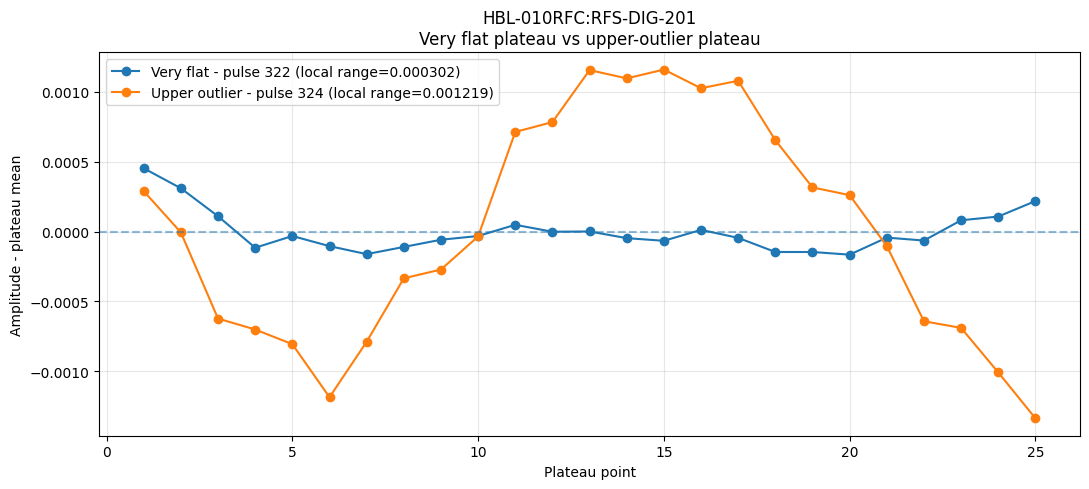

,type,pulse,max_minus_min,mean_window_range,std
0,Very flat,322,0.000618,0.000302,0.000146
1,Upper outlier,324,0.002495,0.001219,0.000783


In [71]:
WINDOW_SIZE = 6
cavity_name = "HBL-010RFC:RFS-DIG-201"

# --------------------------------------------------
# 1. Get one very flat pulse
# --------------------------------------------------
temp_stats = window_stats_all[
    window_stats_all["cavity"] == cavity_name
].copy()

very_flat_row = temp_stats.loc[
    temp_stats["mean_window_range"].idxmin()
]

flat_pulse = int(very_flat_row["pulse"])


# --------------------------------------------------
# 2. Get one upper-outlier pulse
# --------------------------------------------------
temp_outliers = upper_outliers_dd_df[
    upper_outliers_dd_df["cavity"] == cavity_name
].copy()

# choose the strongest upper outlier
outlier_row = temp_outliers.loc[
    temp_outliers["mean_window_range"].idxmax()
]

outlier_pulse = int(outlier_row["pulse"])


# --------------------------------------------------
# 3. Extract plateau function
# --------------------------------------------------
cavity_df = dd_only[
    dd_only["cavity"] == cavity_name
].reset_index(drop=True)


def extract_plateau(pulse_number):

    y = cavity_df.loc[
        pulse_number - 1,
        value_columns
    ].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau

    return y[start:end]


flat_normal = extract_plateau(flat_pulse)
flat_outlier = extract_plateau(outlier_pulse)


# --------------------------------------------------
# 4. Function for metrics
# --------------------------------------------------
def plateau_metrics(flat, window_size=6):

    window_ranges = []

    for j in range(
        0,
        len(flat) - window_size + 1,
        window_size
    ):
        window = flat[j:j + window_size]

        window_ranges.append(
            window.max() - window.min()
        )

    return {
        "max_minus_min": flat.max() - flat.min(),
        "mean_window_range": np.mean(window_ranges),
        "std": flat.std()
    }


m_normal = plateau_metrics(flat_normal, WINDOW_SIZE)
m_outlier = plateau_metrics(flat_outlier, WINDOW_SIZE)


# --------------------------------------------------
# 5. Center both plateaux
# --------------------------------------------------
flat_normal_centered = (
    flat_normal - flat_normal.mean()
)

flat_outlier_centered = (
    flat_outlier - flat_outlier.mean()
)


# --------------------------------------------------
# 6. Plot comparison
# --------------------------------------------------
plt.figure(figsize=(11, 5))

plt.plot(
    np.arange(1, len(flat_normal_centered) + 1),
    flat_normal_centered,
    marker="o",
    label=(
        f"Very flat - pulse {flat_pulse} "
        f"(local range={m_normal['mean_window_range']:.6f})"
    )
)

plt.plot(
    np.arange(1, len(flat_outlier_centered) + 1),
    flat_outlier_centered,
    marker="o",
    label=(
        f"Upper outlier - pulse {outlier_pulse} "
        f"(local range={m_outlier['mean_window_range']:.6f})"
    )
)

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Plateau point")
plt.ylabel("Amplitude - plateau mean")

plt.title(
    f"{cavity_name}\n"
    "Very flat plateau vs upper-outlier plateau"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Show numerical comparison
# --------------------------------------------------
comparison = pd.DataFrame({
    "type": [
        "Very flat",
        "Upper outlier"
    ],
    "pulse": [
        flat_pulse,
        outlier_pulse
    ],
    "max_minus_min": [
        m_normal["max_minus_min"],
        m_outlier["max_minus_min"]
    ],
    "mean_window_range": [
        m_normal["mean_window_range"],
        m_outlier["mean_window_range"]
    ],
    "std": [
        m_normal["std"],
        m_outlier["std"]
    ]
})

display(comparison)

In [74]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [73]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.9/281.9 MB 27.4 MB/s  0:00:10m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 25.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 26.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 27.3 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━ 7/8 [tensorflow]  WARNING: The scripts saved_model_cli, tf_upgrade_v2, tflite_convert and toco are installed in '/lustre/home/extusers/udlc4dd19/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [tensorflow]
Note: you may need to restart the kernel to use updated packages.


In [75]:
cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

# DD = label 0
dd_model = dataset[
    (dataset["label"] == 0) &
    (dataset["cavity"].isin(cavity_names))
].copy()

# numéro du pulse à l'intérieur de chaque cavité
dd_model["pulse"] = (
    dd_model.groupby("cavity").cumcount() + 1
)

# upper outliers que tu avais trouvés
bad_keys = set(
    zip(
        upper_outliers_dd_df["cavity"],
        upper_outliers_dd_df["pulse"]
    )
)

mask_good = [
    (cavity, pulse) not in bad_keys
    for cavity, pulse in zip(
        dd_model["cavity"],
        dd_model["pulse"]
    )
]

dd_clean = dd_model.loc[mask_good].reset_index(drop=True)

print("DD total :", len(dd_model))
print("Outliers removed :", len(dd_model) - len(dd_clean))
print("DD clean :", len(dd_clean))

DD total : 1747
Outliers removed : 27
DD clean : 1720


In [110]:
FIXED_LEN = 15

def resample_plateau(flat, fixed_len=24):
    flat = np.asarray(flat, dtype=float)

    x_old = np.linspace(0, 1, len(flat))
    x_new = np.linspace(0, 1, fixed_len)

    return np.interp(x_new, x_old, flat)

In [111]:
def extract_fixed_plateau(row, fixed_len=24):

    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau
    flat = y[start:end]

    # éviter les plateaux trop courts
    if len(flat) < 6:
        return None

    flat_fixed = resample_plateau(
        flat,
        fixed_len=fixed_len
    )

    return flat_fixed

In [112]:
plateau_vectors = []
metadata = []

for idx, row in dd_clean.iterrows():

    flat_fixed = extract_fixed_plateau(
        row,
        fixed_len=FIXED_LEN
    )

    if flat_fixed is not None:

        plateau_vectors.append(flat_fixed)

        metadata.append({
            "cavity": row["cavity"],
            "pulse": row["pulse"]
        })

X_plateau = np.vstack(plateau_vectors)

metadata = pd.DataFrame(metadata)

print("X plateau shape :", X_plateau.shape)
display(metadata.head())

X plateau shape : (1697, 15)


,cavity,pulse
0,HBL-010RFC:RFS-DIG-201,10
1,HBL-010RFC:RFS-DIG-101,10
2,HBL-010RFC:RFS-DIG-301,10
3,HBL-010RFC:RFS-DIG-401,10
4,HBL-010RFC:RFS-DIG-401,11


In [113]:
X_train, X_temp, meta_train, meta_temp = train_test_split(
    X_plateau,
    metadata,
    test_size=0.40,
    random_state=42
)

X_val, X_test, meta_val, meta_test = train_test_split(
    X_temp,
    meta_temp,
    test_size=0.50,
    random_state=42
)

print("Train :", X_train.shape)
print("Val   :", X_val.shape)
print("Test  :", X_test.shape)

Train : (1018, 15)
Val   : (339, 15)
Test  : (340, 15)


In [114]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [115]:
def build_autoencoder(input_dim):

    input_layer = Input(shape=(input_dim,))

    encoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(input_layer)

    latent = Dense(4)(encoder)
    latent = LeakyReLU(
        negative_slope=0.075
    )(latent)

    decoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(latent)

    output_layer = Dense(input_dim)(decoder)

    model = Model(
        input_layer,
        output_layer
    )

    model.compile(
        loss="mean_squared_error",
        optimizer=Adam(
            learning_rate=1e-4
        )
    )

    return model

In [116]:
from tensorflow.keras import backend as K

K.clear_session()

input_dim = X_train_scaled.shape[1]

ae = build_autoencoder(input_dim)

In [117]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = ae.fit(
    X_train_scaled,
    X_train_scaled,
    validation_data=(
        X_val_scaled,
        X_val_scaled
    ),
    epochs=500,
    batch_size=16,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.0971 - val_loss: 1.1314
Epoch 2/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0629 - val_loss: 1.0964
Epoch 3/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0286 - val_loss: 1.0618
Epoch 4/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9967 - val_loss: 1.0299
Epoch 5/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9642 - val_loss: 0.9945
Epoch 6/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9290 - val_loss: 0.9567
Epoch 7/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8920 - val_loss: 0.9165
Epoch 8/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8533 - val_loss: 0.8757
Epoch 9/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8138 - val_loss: 0.8341
Epoch 10/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7742 - val_loss: 0.7926
Epoch 11/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7353 - val_loss: 0.7521
Epoch 12/500
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6

In [121]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
def residual_features(residual):

    return pd.DataFrame({
        "res_mean": residual.mean(axis=1),

        "res_std": residual.std(axis=1),

        "res_max_minus_min":
            residual.max(axis=1) - residual.min(axis=1),

        "res_mae":
            np.mean(np.abs(residual), axis=1),

        "res_mse":
            np.mean(residual**2, axis=1),

        "res_max_abs":
            np.max(np.abs(residual), axis=1)
    })
# Reconstruction
X_val_rec = ae.predict(
    X_val_scaled,
    verbose=0
)

X_test_rec = ae.predict(
    X_test_scaled,
    verbose=0
)

# Residuals
res_val = X_val_scaled - X_val_rec
res_test = X_test_scaled - X_test_rec

# Statistical features
features_val = residual_features(res_val)
features_test = residual_features(res_test)

print("DD validation features:", features_val.shape)
print("DD test features:", features_test.shape)

display(features_val.head())
label1 = dataset[
    (dataset["label"] == 1) &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

print("Total label 1 pulses:", len(label1))
print()
print(label1["cavity"].value_counts())
trip_vectors = []
trip_metadata = []

for idx, row in label1.iterrows():

    flat_fixed = extract_fixed_plateau(
        row,
        fixed_len=15
    )

    if flat_fixed is not None:

        trip_vectors.append(flat_fixed)

        trip_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })

X_trip_all = np.vstack(trip_vectors)

trip_metadata = pd.DataFrame(
    trip_metadata
)

print("Usable label 1 plateaux:", X_trip_all.shape)
display(trip_metadata.head())

DD validation features: (339, 6)
DD test features: (340, 6)


,res_mean,res_std,res_max_minus_min,res_mae,res_mse,res_max_abs
0,-0.000439,0.000889,0.003936,0.000743,9.833832e-07,0.002004
1,0.001030,0.001029,0.003209,0.001223,2.119546e-06,0.002452
2,0.002219,0.000480,0.001794,0.002219,5.155893e-06,0.003216
3,0.001030,0.001061,0.003632,0.001273,2.186747e-06,0.002416
4,-0.000439,0.000648,0.002122,0.000629,6.128133e-07,0.001506


Total label 1 pulses: 234

cavity
HBL-010RFC:RFS-DIG-201    59
HBL-010RFC:RFS-DIG-101    59
HBL-010RFC:RFS-DIG-301    59
HBL-010RFC:RFS-DIG-401    57
Name: count, dtype: int64
Usable label 1 plateaux: (172, 15)


,original_index,cavity
0,1,HBL-010RFC:RFS-DIG-101
1,3,HBL-010RFC:RFS-DIG-401
2,4,HBL-010RFC:RFS-DIG-401
3,7,HBL-010RFC:RFS-DIG-101
4,10,HBL-010RFC:RFS-DIG-101


In [122]:
# ---------------------------------------------------------
# Split the 172 usable trip plateaux into validation/test
# ---------------------------------------------------------

from sklearn.model_selection import train_test_split

trip_indices = np.arange(len(X_trip_all))

idx_trip_val, idx_trip_test = train_test_split(
    trip_indices,
    test_size=0.50,
    random_state=42,
    stratify=trip_metadata["cavity"]
)

X_trip_val = X_trip_all[idx_trip_val]
X_trip_test = X_trip_all[idx_trip_test]

trip_meta_val = trip_metadata.iloc[idx_trip_val].reset_index(drop=True)
trip_meta_test = trip_metadata.iloc[idx_trip_test].reset_index(drop=True)

print("Trip validation:", len(X_trip_val))
print("Trip test:", len(X_trip_test))

print("\nTrip validation per cavity:")
print(trip_meta_val["cavity"].value_counts())

print("\nTrip test per cavity:")
print(trip_meta_test["cavity"].value_counts())

Trip validation: 86
Trip test: 86

Trip validation per cavity:
cavity
HBL-010RFC:RFS-DIG-101    30
HBL-010RFC:RFS-DIG-401    28
HBL-010RFC:RFS-DIG-301    14
HBL-010RFC:RFS-DIG-201    14
Name: count, dtype: int64

Trip test per cavity:
cavity
HBL-010RFC:RFS-DIG-401    29
HBL-010RFC:RFS-DIG-101    29
HBL-010RFC:RFS-DIG-201    14
HBL-010RFC:RFS-DIG-301    14
Name: count, dtype: int64


DD validation features: (339, 6)
DD test features: (340, 6)

Total label 1: 234
cavity
HBL-010RFC:RFS-DIG-201    59
HBL-010RFC:RFS-DIG-101    59
HBL-010RFC:RFS-DIG-301    59
HBL-010RFC:RFS-DIG-401    57
Name: count, dtype: int64

Usable label 1 plateaux: (172, 15)
cavity
HBL-010RFC:RFS-DIG-101    59
HBL-010RFC:RFS-DIG-401    57
HBL-010RFC:RFS-DIG-201    28
HBL-010RFC:RFS-DIG-301    28
Name: count, dtype: int64

Trip validation: 86
Trip test: 86

Trip validation by cavity:
cavity
HBL-010RFC:RFS-DIG-101    30
HBL-010RFC:RFS-DIG-401    28
HBL-010RFC:RFS-DIG-301    14
HBL-010RFC:RFS-DIG-201    14
Name: count, dtype: int64

Trip test by cavity:
cavity
HBL-010RFC:RFS-DIG-401    29
HBL-010RFC:RFS-DIG-101    29
HBL-010RFC:RFS-DIG-201    14
HBL-010RFC:RFS-DIG-301    14
Name: count, dtype: int64

Balanced DD validation: 86
Balanced DD test: 86

Trip validation features: (86, 6)
Trip test features: (86, 6)

Classifier pool:
label
0    86
1    86
Name: count, dtype: int64

XGBoost train: (120, 6)


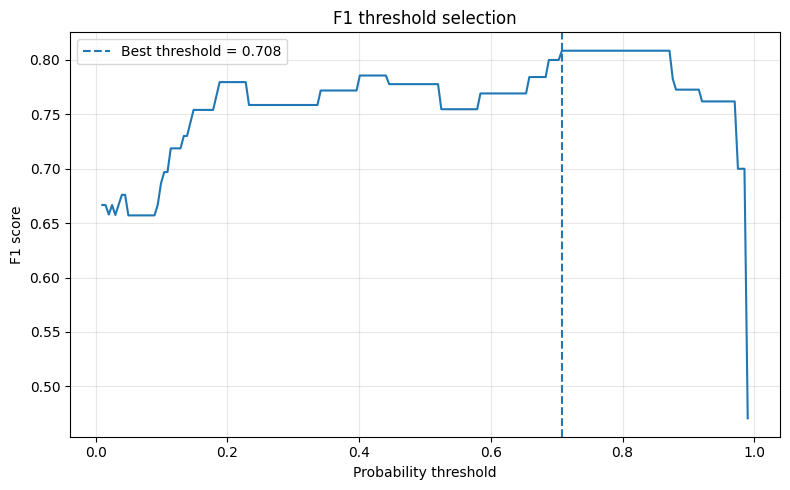


Final test:
label
0    86
1    86
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

           0     0.7600    0.8837    0.8172        86
           1     0.8611    0.7209    0.7848        86

    accuracy                         0.8023       172
   macro avg     0.8106    0.8023    0.8010       172
weighted avg     0.8106    0.8023    0.8010       172

F1: 0.7848101265822784
Precision: 0.8611111111111112
Recall: 0.7209302325581395
ROC AUC: 0.8845997836668469
PR AUC: 0.9083195818909655

Confusion matrix:
[[76 10]
 [24 62]]


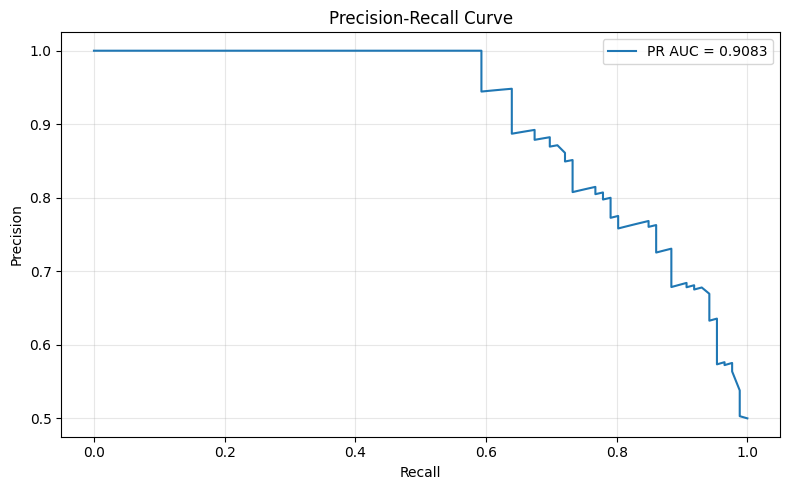

In [123]:
# ============================================================
# AFTER AUTOENCODER TRAINING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier


# ============================================================
# 1. RESIDUAL FEATURE FUNCTION
# ============================================================

def residual_features(residual):

    return pd.DataFrame({
        "res_mean":
            residual.mean(axis=1),

        "res_std":
            residual.std(axis=1),

        "res_max_minus_min":
            residual.max(axis=1)
            - residual.min(axis=1),

        "res_mae":
            np.mean(
                np.abs(residual),
                axis=1
            ),

        "res_mse":
            np.mean(
                residual**2,
                axis=1
            ),

        "res_max_abs":
            np.max(
                np.abs(residual),
                axis=1
            )
    })


# ============================================================
# 2. DD VALIDATION + TEST RECONSTRUCTION
# ============================================================

X_val_rec = ae.predict(
    X_val_scaled,
    verbose=0
)

X_test_rec = ae.predict(
    X_test_scaled,
    verbose=0
)

res_val = (
    X_val_scaled
    - X_val_rec
)

res_test = (
    X_test_scaled
    - X_test_rec
)

features_val = residual_features(
    res_val
)

features_test = residual_features(
    res_test
)

print(
    "DD validation features:",
    features_val.shape
)

print(
    "DD test features:",
    features_test.shape
)


# ============================================================
# 3. GET LABEL 1 DATA
# ============================================================

label1 = dataset[
    (dataset["label"] == 1)
    &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

print(
    "\nTotal label 1:",
    len(label1)
)

print(
    label1["cavity"].value_counts()
)


# ============================================================
# 4. EXTRACT 24-POINT TRIP PLATEAUX
# ============================================================

trip_vectors = []
trip_metadata = []

for idx, row in label1.iterrows():

    flat_fixed = extract_fixed_plateau(
        row,
        fixed_len=15
    )

    if flat_fixed is not None:

        trip_vectors.append(
            flat_fixed
        )

        trip_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })


X_trip_all = np.vstack(
    trip_vectors
)

trip_metadata = pd.DataFrame(
    trip_metadata
)

print(
    "\nUsable label 1 plateaux:",
    X_trip_all.shape
)

print(
    trip_metadata["cavity"].value_counts()
)


# ============================================================
# 5. SPLIT LABEL 1: 50% VALIDATION / 50% TEST
# ============================================================

trip_indices = np.arange(
    len(X_trip_all)
)

idx_trip_val, idx_trip_test = train_test_split(
    trip_indices,
    test_size=0.50,
    random_state=42,
    stratify=trip_metadata["cavity"]
)

X_trip_val = X_trip_all[
    idx_trip_val
]

X_trip_test = X_trip_all[
    idx_trip_test
]

trip_meta_val = (
    trip_metadata
    .iloc[idx_trip_val]
    .reset_index(drop=True)
)

trip_meta_test = (
    trip_metadata
    .iloc[idx_trip_test]
    .reset_index(drop=True)
)

print(
    "\nTrip validation:",
    len(X_trip_val)
)

print(
    "Trip test:",
    len(X_trip_test)
)

print(
    "\nTrip validation by cavity:"
)

print(
    trip_meta_val[
        "cavity"
    ].value_counts()
)

print(
    "\nTrip test by cavity:"
)

print(
    trip_meta_test[
        "cavity"
    ].value_counts()
)


# ============================================================
# 6. SAMPLE MATCHING DD BY CAVITY
# ============================================================

def sample_dd_by_cavity(
    dd_features,
    dd_meta,
    trip_meta,
    random_state=42
):

    selected_indices = []

    for cavity_name, n_needed in (
        trip_meta["cavity"]
        .value_counts()
        .items()
    ):

        available = dd_meta[
            dd_meta["cavity"]
            == cavity_name
        ].index

        if len(available) < n_needed:

            raise ValueError(
                f"Not enough DD samples for "
                f"{cavity_name}. "
                f"Need {n_needed}, "
                f"have {len(available)}."
            )

        sampled = (
            pd.Series(
                available
            )
            .sample(
                n=n_needed,
                random_state=random_state
            )
            .tolist()
        )

        selected_indices.extend(
            sampled
        )

    return (
        dd_features
        .loc[selected_indices]
        .reset_index(drop=True)
    )


features_dd_val_bal = sample_dd_by_cavity(
    features_val,
    meta_val.reset_index(drop=True),
    trip_meta_val,
    random_state=42
)

features_dd_test_bal = sample_dd_by_cavity(
    features_test,
    meta_test.reset_index(drop=True),
    trip_meta_test,
    random_state=43
)

print(
    "\nBalanced DD validation:",
    len(features_dd_val_bal)
)

print(
    "Balanced DD test:",
    len(features_dd_test_bal)
)


# ============================================================
# 7. SCALE TRIP DATA
# ============================================================

# IMPORTANT:
# scaler was fitted ONLY on DD training data

X_trip_val_scaled = scaler.transform(
    X_trip_val
)

X_trip_test_scaled = scaler.transform(
    X_trip_test
)


# ============================================================
# 8. TRIP RECONSTRUCTION
# ============================================================

X_trip_val_rec = ae.predict(
    X_trip_val_scaled,
    verbose=0
)

X_trip_test_rec = ae.predict(
    X_trip_test_scaled,
    verbose=0
)


# ============================================================
# 9. TRIP RESIDUAL FEATURES
# ============================================================

res_trip_val = (
    X_trip_val_scaled
    - X_trip_val_rec
)

res_trip_test = (
    X_trip_test_scaled
    - X_trip_test_rec
)

features_trip_val = residual_features(
    res_trip_val
)

features_trip_test = residual_features(
    res_trip_test
)

print(
    "\nTrip validation features:",
    features_trip_val.shape
)

print(
    "Trip test features:",
    features_trip_test.shape
)


# ============================================================
# 10. BUILD BALANCED XGBOOST DEVELOPMENT DATA
# ============================================================

dd_clf = (
    features_dd_val_bal
    .copy()
)

dd_clf["label"] = 0


trip_clf = (
    features_trip_val
    .copy()
)

trip_clf["label"] = 1


clf_pool = pd.concat(
    [
        dd_clf,
        trip_clf
    ],
    ignore_index=True
)

print(
    "\nClassifier pool:"
)

print(
    clf_pool[
        "label"
    ].value_counts()
)


# ============================================================
# 11. XGBOOST TRAIN / THRESHOLD VALIDATION SPLIT
# ============================================================

X_clf = clf_pool.drop(
    columns="label"
)

y_clf = clf_pool[
    "label"
]

(
    X_xgb_train,
    X_thresh_val,
    y_xgb_train,
    y_thresh_val
) = train_test_split(
    X_clf,
    y_clf,
    test_size=0.30,
    random_state=42,
    stratify=y_clf
)

print(
    "\nXGBoost train:",
    X_xgb_train.shape
)

print(
    "Threshold validation:",
    X_thresh_val.shape
)


# ============================================================
# 12. TRAIN XGBOOST
# ============================================================

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,

    subsample=0.8,
    colsample_bytree=0.8,

    eval_metric="logloss",
    random_state=42
)

xgb.fit(
    X_xgb_train,
    y_xgb_train
)


# ============================================================
# 13. FIND BEST F1 THRESHOLD
# ============================================================

val_prob = xgb.predict_proba(
    X_thresh_val
)[:, 1]

thresholds = np.linspace(
    0.01,
    0.99,
    199
)

f1_scores = []

for threshold in thresholds:

    pred = (
        val_prob
        >= threshold
    ).astype(int)

    score = f1_score(
        y_thresh_val,
        pred
    )

    f1_scores.append(
        score
    )


best_idx = np.argmax(
    f1_scores
)

best_threshold = thresholds[
    best_idx
]

best_val_f1 = f1_scores[
    best_idx
]

print(
    "\nBest threshold:",
    best_threshold
)

print(
    "Best validation F1:",
    best_val_f1
)


# ============================================================
# 14. PLOT F1 VS THRESHOLD
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    thresholds,
    f1_scores
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=(
        f"Best threshold = "
        f"{best_threshold:.3f}"
    )
)

plt.xlabel(
    "Probability threshold"
)

plt.ylabel(
    "F1 score"
)

plt.title(
    "F1 threshold selection"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 15. BUILD FINAL UNTOUCHED TEST SET
# ============================================================

dd_final = (
    features_dd_test_bal
    .copy()
)

dd_final["label"] = 0


trip_final = (
    features_trip_test
    .copy()
)

trip_final["label"] = 1


final_test = pd.concat(
    [
        dd_final,
        trip_final
    ],
    ignore_index=True
)

final_test = (
    final_test
    .sample(
        frac=1,
        random_state=42
    )
    .reset_index(drop=True)
)


X_final_test = final_test.drop(
    columns="label"
)

y_final_test = final_test[
    "label"
]

print(
    "\nFinal test:"
)

print(
    y_final_test.value_counts()
)


# ============================================================
# 16. FINAL TEST PROBABILITIES
# ============================================================

test_prob = xgb.predict_proba(
    X_final_test
)[:, 1]


# ============================================================
# 17. APPLY VALIDATION-SELECTED THRESHOLD
# ============================================================

y_final_pred = (
    test_prob
    >= best_threshold
).astype(int)


# ============================================================
# 18. FINAL CLASSIFICATION METRICS
# ============================================================

print(
    "\nClassification report:"
)

print(
    classification_report(
        y_final_test,
        y_final_pred,
        digits=4
    )
)


final_f1 = f1_score(
    y_final_test,
    y_final_pred
)

final_precision = precision_score(
    y_final_test,
    y_final_pred
)

final_recall = recall_score(
    y_final_test,
    y_final_pred
)

roc_auc = roc_auc_score(
    y_final_test,
    test_prob
)


print(
    "F1:",
    final_f1
)

print(
    "Precision:",
    final_precision
)

print(
    "Recall:",
    final_recall
)

print(
    "ROC AUC:",
    roc_auc
)


# ============================================================
# 19. PR AUC
# ============================================================

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_final_test,
        test_prob
    )
)

pr_auc = auc(
    recall_curve,
    precision_curve
)

print(
    "PR AUC:",
    pr_auc
)


# ============================================================
# 20. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_final_test,
    y_final_pred
)

print(
    "\nConfusion matrix:"
)

print(
    cm
)


# ============================================================
# 21. PRECISION-RECALL CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    recall_curve,
    precision_curve,
    label=(
        f"PR AUC = "
        f"{pr_auc:.4f}"
    )
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Precision-Recall Curve"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [105]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 MB 20.7 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 22.7 MB/s  0:00:13m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]
Note: you may need to restart the kernel to use updated packages.



FIXED LENGTH = 12
Usable DD: (1697, 12)
DD train: (1018, 12)
DD val: (339, 12)
DD test: (340, 12)
AE epochs: 500
Best val loss: 0.00047473120503127575
Usable trips: (172, 12)
Trip val: 86
Trip test: 86

Best threshold: 0.2921212121212121
Validation F1: 0.8
Test F1: 0.7789473684210526
Precision: 0.7115384615384616
Recall: 0.8604651162790697
ROC AUC: 0.8650621957815035
PR AUC: 0.8954264407160013
Confusion matrix:
[[56 30]
 [12 74]]

FIXED LENGTH = 15
Usable DD: (1697, 15)
DD train: (1018, 15)
DD val: (339, 15)
DD test: (340, 15)
AE epochs: 500
Best val loss: 0.0005516615347005427
Usable trips: (172, 15)
Trip val: 86
Trip test: 86

Best threshold: 0.5841414141414141
Validation F1: 0.8979591836734694
Test F1: 0.8375
Precision: 0.9054054054054054
Recall: 0.7790697674418605
ROC AUC: 0.8865603028664144
PR AUC: 0.9167172525795063
Confusion matrix:
[[79  7]
 [19 67]]

FIXED LENGTH = 18
Usable DD: (1697, 18)
DD train: (1018, 18)
DD val: (339, 18)
DD test: (340, 18)
AE epochs: 500
Best val loss:

,fixed_len,dd_usable,trip_usable,ae_epochs,best_ae_val_loss,best_threshold,validation_f1,test_f1,precision,recall,roc_auc,pr_auc
0,12,1697,172,500,0.000475,0.292121,0.800000,0.778947,0.711538,0.860465,0.865062,0.895426
1,15,1697,172,500,0.000552,0.584141,0.897959,0.837500,0.905405,0.779070,0.886560,0.916717
2,18,1697,172,500,0.000821,0.460404,0.823529,0.768362,0.747253,0.790698,0.837953,0.874849
3,24,1697,172,500,0.000460,0.732626,0.880000,0.835443,0.916667,0.767442,0.908396,0.931370


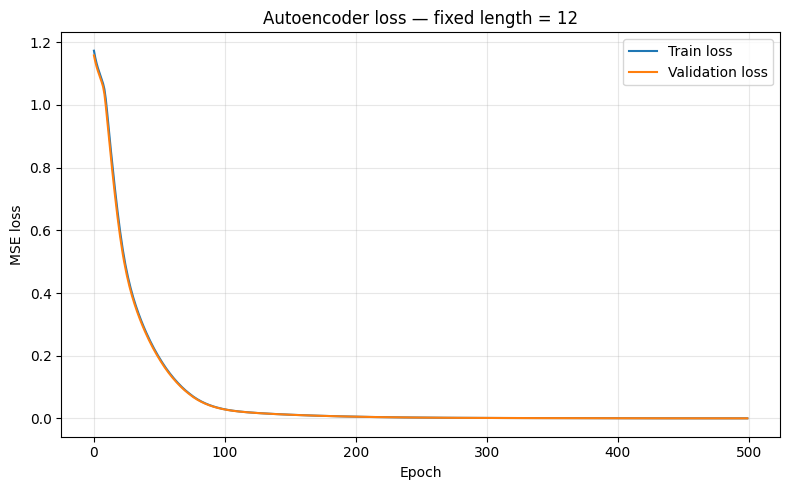

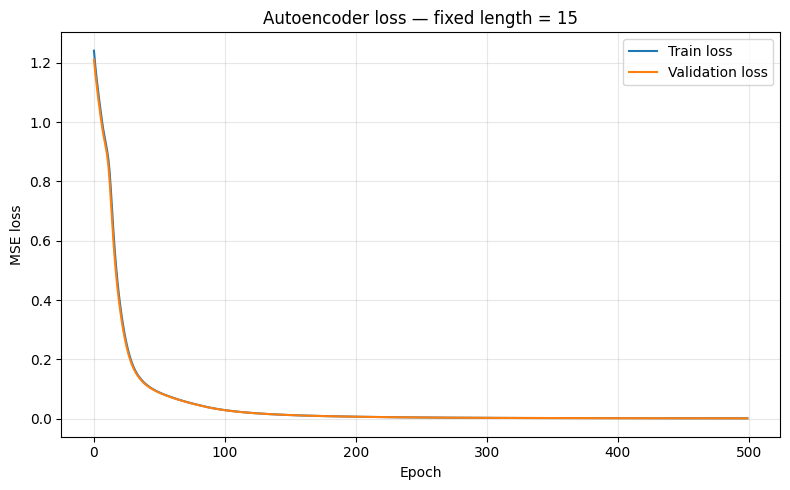

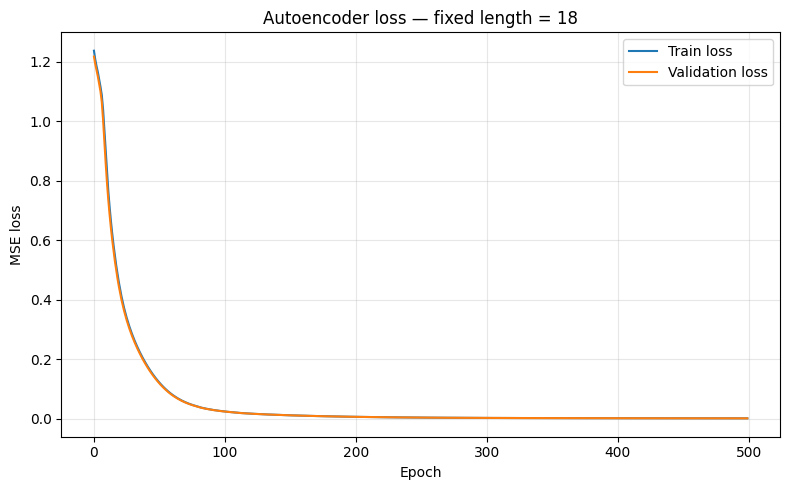

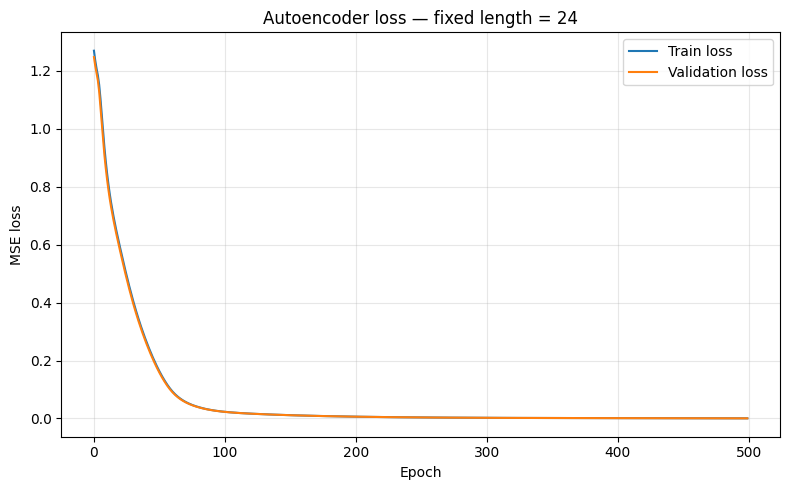

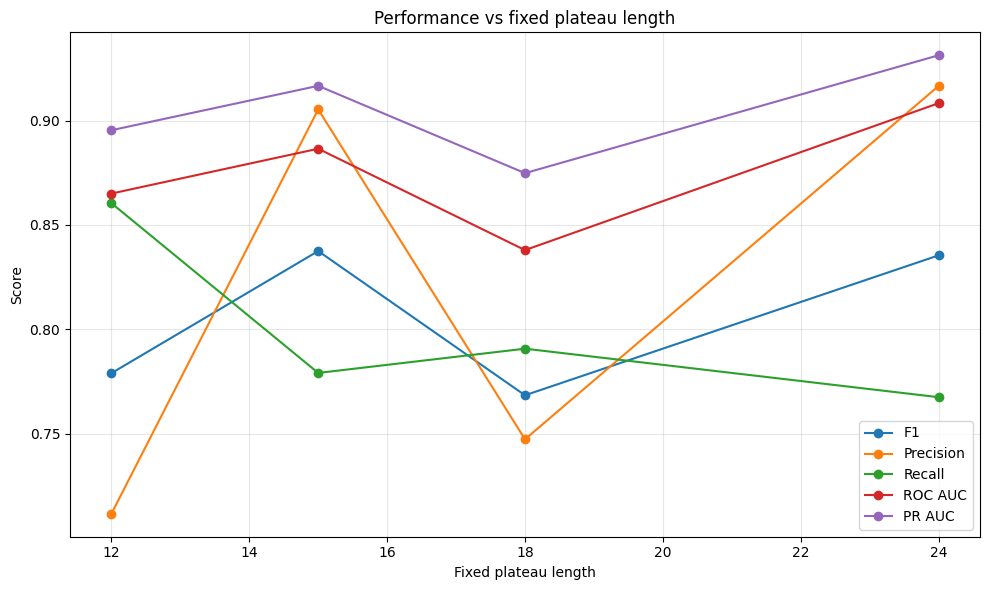

In [130]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

from xgboost import XGBClassifier


# ============================================================
# SETTINGS
# ============================================================

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

fixed_lengths = [12, 15, 18, 24]

EPOCHS = 500
BATCH_SIZE = 16
PATIENCE = 20
SEED = 42


# ============================================================
# FUNCTIONS
# ============================================================

def resample_plateau(flat, fixed_len):
    flat = np.asarray(flat, dtype=float)

    x_old = np.linspace(0, 1, len(flat))
    x_new = np.linspace(0, 1, fixed_len)

    return np.interp(x_new, x_old, flat)


def extract_fixed_plateau(row, fixed_len):
    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau
    flat = y[start:end]

    if len(flat) < 6:
        return None

    return resample_plateau(flat, fixed_len)


def build_autoencoder(input_dim):

    input_layer = Input(shape=(input_dim,))

    encoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(input_layer)

    latent = Dense(4)(encoder)
    latent = LeakyReLU(
        negative_slope=0.075
    )(latent)

    decoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(latent)

    output_layer = Dense(input_dim)(decoder)

    model = Model(
        input_layer,
        output_layer
    )

    model.compile(
        loss="mean_squared_error",
        optimizer=Adam(
            learning_rate=1e-4
        )
    )

    return model


def residual_features(residual):

    return pd.DataFrame({
        "res_mean": residual.mean(axis=1),

        "res_std": residual.std(axis=1),

        "res_max_minus_min":
            residual.max(axis=1)
            - residual.min(axis=1),

        "res_mae":
            np.mean(np.abs(residual), axis=1),

        "res_mse":
            np.mean(residual**2, axis=1),

        "res_max_abs":
            np.max(np.abs(residual), axis=1)
    })


# ============================================================
# CLEAN DD
# ============================================================

dd_model = dataset[
    (dataset["label"] == 0)
    &
    (dataset["cavity"].isin(cavity_names))
].copy()

dd_model["pulse"] = (
    dd_model
    .groupby("cavity")
    .cumcount() + 1
)

bad_keys = set(
    zip(
        upper_outliers_dd_df["cavity"],
        upper_outliers_dd_df["pulse"]
    )
)

mask_good = [
    (cavity, pulse) not in bad_keys
    for cavity, pulse in zip(
        dd_model["cavity"],
        dd_model["pulse"]
    )
]

dd_clean = (
    dd_model
    .loc[mask_good]
    .reset_index(drop=True)
)


# ============================================================
# LABEL 1
# ============================================================

label1 = dataset[
    (dataset["label"] == 1)
    &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)


# ============================================================
# FULL EXPERIMENT FUNCTION
# ============================================================

def run_experiment(FIXED_LEN):

    print("\n" + "=" * 70)
    print(f"FIXED LENGTH = {FIXED_LEN}")
    print("=" * 70)

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    # --------------------------------------------------------
    # DD plateaux
    # --------------------------------------------------------

    dd_vectors = []
    dd_metadata = []

    for _, row in dd_clean.iterrows():

        flat_fixed = extract_fixed_plateau(
            row,
            fixed_len=FIXED_LEN
        )

        if flat_fixed is not None:

            dd_vectors.append(flat_fixed)

            dd_metadata.append({
                "cavity": row["cavity"],
                "pulse": row["pulse"]
            })

    X_dd_all = np.vstack(dd_vectors)
    dd_metadata = pd.DataFrame(dd_metadata)

    print("Usable DD:", X_dd_all.shape)

    # --------------------------------------------------------
    # DD split 60 / 20 / 20
    # --------------------------------------------------------

    X_train, X_temp, meta_train, meta_temp = train_test_split(
        X_dd_all,
        dd_metadata,
        test_size=0.40,
        random_state=SEED,
        stratify=dd_metadata["cavity"]
    )

    X_val, X_test, meta_val, meta_test = train_test_split(
        X_temp,
        meta_temp,
        test_size=0.50,
        random_state=SEED,
        stratify=meta_temp["cavity"]
    )

    print("DD train:", X_train.shape)
    print("DD val:", X_val.shape)
    print("DD test:", X_test.shape)

    # --------------------------------------------------------
    # scaling
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    # --------------------------------------------------------
    # fresh autoencoder
    # --------------------------------------------------------

    K.clear_session()

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    ae = build_autoencoder(FIXED_LEN)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = ae.fit(
        X_train_scaled,
        X_train_scaled,
        validation_data=(
            X_val_scaled,
            X_val_scaled
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
        callbacks=[early_stop]
    )

    print(
        "AE epochs:",
        len(history.history["loss"])
    )

    print(
        "Best val loss:",
        min(history.history["val_loss"])
    )

    # --------------------------------------------------------
    # DD residual features
    # --------------------------------------------------------

    X_val_rec = ae.predict(
        X_val_scaled,
        verbose=0
    )

    X_test_rec = ae.predict(
        X_test_scaled,
        verbose=0
    )

    res_val = (
        X_val_scaled
        - X_val_rec
    )

    res_test = (
        X_test_scaled
        - X_test_rec
    )

    features_val = residual_features(res_val)
    features_test = residual_features(res_test)

    # --------------------------------------------------------
    # Trip plateaux
    # --------------------------------------------------------

    trip_vectors = []
    trip_metadata = []

    for idx, row in label1.iterrows():

        flat_fixed = extract_fixed_plateau(
            row,
            fixed_len=FIXED_LEN
        )

        if flat_fixed is not None:

            trip_vectors.append(flat_fixed)

            trip_metadata.append({
                "original_index": idx,
                "cavity": row["cavity"]
            })

    X_trip_all = np.vstack(trip_vectors)
    trip_metadata = pd.DataFrame(trip_metadata)

    print(
        "Usable trips:",
        X_trip_all.shape
    )

    # --------------------------------------------------------
    # split trips 50 / 50
    # --------------------------------------------------------

    trip_indices = np.arange(
        len(X_trip_all)
    )

    idx_trip_val, idx_trip_test = train_test_split(
        trip_indices,
        test_size=0.50,
        random_state=SEED,
        stratify=trip_metadata["cavity"]
    )

    X_trip_val = X_trip_all[idx_trip_val]
    X_trip_test = X_trip_all[idx_trip_test]

    trip_meta_val = (
        trip_metadata
        .iloc[idx_trip_val]
        .reset_index(drop=True)
    )

    trip_meta_test = (
        trip_metadata
        .iloc[idx_trip_test]
        .reset_index(drop=True)
    )

    print(
        "Trip val:",
        len(X_trip_val)
    )

    print(
        "Trip test:",
        len(X_trip_test)
    )

    # --------------------------------------------------------
    # reset DD indices
    # --------------------------------------------------------

    meta_val = meta_val.reset_index(drop=True)
    meta_test = meta_test.reset_index(drop=True)

    features_val = features_val.reset_index(drop=True)
    features_test = features_test.reset_index(drop=True)

    # --------------------------------------------------------
    # sample matching DD per cavity
    # --------------------------------------------------------

    def sample_matching_dd(
        features,
        metadata,
        trip_meta,
        random_state
    ):

        selected = []

        for cavity_name, n_needed in (
            trip_meta["cavity"]
            .value_counts()
            .items()
        ):

            available = metadata[
                metadata["cavity"]
                == cavity_name
            ].index

            if len(available) < n_needed:
                raise ValueError(
                    f"{cavity_name}: need "
                    f"{n_needed} DD, have "
                    f"{len(available)}"
                )

            chosen = (
                pd.Series(available)
                .sample(
                    n=n_needed,
                    random_state=random_state
                )
                .tolist()
            )

            selected.extend(chosen)

        return (
            features
            .loc[selected]
            .reset_index(drop=True)
        )

    features_dd_val_bal = sample_matching_dd(
        features_val,
        meta_val,
        trip_meta_val,
        SEED
    )

    features_dd_test_bal = sample_matching_dd(
        features_test,
        meta_test,
        trip_meta_test,
        SEED + 1
    )

    # --------------------------------------------------------
    # trip reconstruction
    # --------------------------------------------------------

    X_trip_val_scaled = scaler.transform(
        X_trip_val
    )

    X_trip_test_scaled = scaler.transform(
        X_trip_test
    )

    X_trip_val_rec = ae.predict(
        X_trip_val_scaled,
        verbose=0
    )

    X_trip_test_rec = ae.predict(
        X_trip_test_scaled,
        verbose=0
    )

    res_trip_val = (
        X_trip_val_scaled
        - X_trip_val_rec
    )

    res_trip_test = (
        X_trip_test_scaled
        - X_trip_test_rec
    )

    features_trip_val = residual_features(
        res_trip_val
    )

    features_trip_test = residual_features(
        res_trip_test
    )

    # --------------------------------------------------------
    # classifier pool
    # --------------------------------------------------------

    dd_clf = features_dd_val_bal.copy()
    dd_clf["label"] = 0

    trip_clf = features_trip_val.copy()
    trip_clf["label"] = 1

    clf_pool = pd.concat(
        [dd_clf, trip_clf],
        ignore_index=True
    )

    X_clf = clf_pool.drop(
        columns="label"
    )

    y_clf = clf_pool["label"]

    # --------------------------------------------------------
    # XGBoost train / threshold validation
    # --------------------------------------------------------

    X_xgb_train, X_thresh_val, y_xgb_train, y_thresh_val = (
        train_test_split(
            X_clf,
            y_clf,
            test_size=0.30,
            random_state=SEED,
            stratify=y_clf
        )
    )

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=SEED
    )

    xgb.fit(
        X_xgb_train,
        y_xgb_train
    )

    # --------------------------------------------------------
    # best threshold on validation
    # --------------------------------------------------------

    val_prob = xgb.predict_proba(
        X_thresh_val
    )[:, 1]

    thresholds = np.linspace(
        0.01,
        0.99,
        199
    )

    f1_scores = []

    for threshold in thresholds:

        pred = (
            val_prob >= threshold
        ).astype(int)

        f1_scores.append(
            f1_score(
                y_thresh_val,
                pred
            )
        )

    best_idx = np.argmax(
        f1_scores
    )

    best_threshold = thresholds[
        best_idx
    ]

    best_val_f1 = f1_scores[
        best_idx
    ]

    # --------------------------------------------------------
    # final test
    # --------------------------------------------------------

    dd_final = features_dd_test_bal.copy()
    dd_final["label"] = 0

    trip_final = features_trip_test.copy()
    trip_final["label"] = 1

    final_test = pd.concat(
        [dd_final, trip_final],
        ignore_index=True
    )

    final_test = (
        final_test
        .sample(
            frac=1,
            random_state=SEED
        )
        .reset_index(drop=True)
    )

    X_final_test = final_test.drop(
        columns="label"
    )

    y_final_test = final_test[
        "label"
    ]

    test_prob = xgb.predict_proba(
        X_final_test
    )[:, 1]

    y_final_pred = (
        test_prob >= best_threshold
    ).astype(int)

    # --------------------------------------------------------
    # metrics
    # --------------------------------------------------------

    final_f1 = f1_score(
        y_final_test,
        y_final_pred
    )

    final_precision = precision_score(
        y_final_test,
        y_final_pred,
        zero_division=0
    )

    final_recall = recall_score(
        y_final_test,
        y_final_pred
    )

    roc_auc = roc_auc_score(
        y_final_test,
        test_prob
    )

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_final_test,
            test_prob
        )
    )

    pr_auc = auc(
        recall_curve,
        precision_curve
    )

    cm = confusion_matrix(
        y_final_test,
        y_final_pred
    )

    print()
    print("Best threshold:", best_threshold)
    print("Validation F1:", best_val_f1)
    print("Test F1:", final_f1)
    print("Precision:", final_precision)
    print("Recall:", final_recall)
    print("ROC AUC:", roc_auc)
    print("PR AUC:", pr_auc)
    print("Confusion matrix:")
    print(cm)

    return {
        "fixed_len": FIXED_LEN,
        "dd_usable": len(X_dd_all),
        "trip_usable": len(X_trip_all),
        "ae_epochs": len(history.history["loss"]),
        "best_ae_val_loss": min(history.history["val_loss"]),
        "best_threshold": best_threshold,
        "validation_f1": best_val_f1,
        "test_f1": final_f1,
        "precision": final_precision,
        "recall": final_recall,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "history": history.history
    }


# ============================================================
# RUN ALL LENGTHS
# ============================================================

results = []

for L in fixed_lengths:

    result = run_experiment(
        FIXED_LEN=L
    )

    results.append(result)


# ============================================================
# RESULTS TABLE
# ============================================================

results_df = pd.DataFrame([
    {
        k: v
        for k, v in result.items()
        if k != "history"
    }
    for result in results
])

display(
    results_df[
        [
            "fixed_len",
            "dd_usable",
            "trip_usable",
            "ae_epochs",
            "best_ae_val_loss",
            "best_threshold",
            "validation_f1",
            "test_f1",
            "precision",
            "recall",
            "roc_auc",
            "pr_auc"
        ]
    ]
)


# ============================================================
# TRAIN / VALIDATION LOSS CURVES
# ONE FIGURE PER LENGTH
# ============================================================

for result in results:

    L = result["fixed_len"]
    h = result["history"]

    plt.figure(figsize=(8, 5))

    plt.plot(
        h["loss"],
        label="Train loss"
    )

    plt.plot(
        h["val_loss"],
        label="Validation loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")

    plt.title(
        f"Autoencoder loss — fixed length = {L}"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# PERFORMANCE VS LENGTH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    results_df["fixed_len"],
    results_df["test_f1"],
    marker="o",
    label="F1"
)

plt.plot(
    results_df["fixed_len"],
    results_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["fixed_len"],
    results_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["fixed_len"],
    results_df["roc_auc"],
    marker="o",
    label="ROC AUC"
)

plt.plot(
    results_df["fixed_len"],
    results_df["pr_auc"],
    marker="o",
    label="PR AUC"
)

plt.xlabel("Fixed plateau length")
plt.ylabel("Score")

plt.title(
    "Performance vs fixed plateau length"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

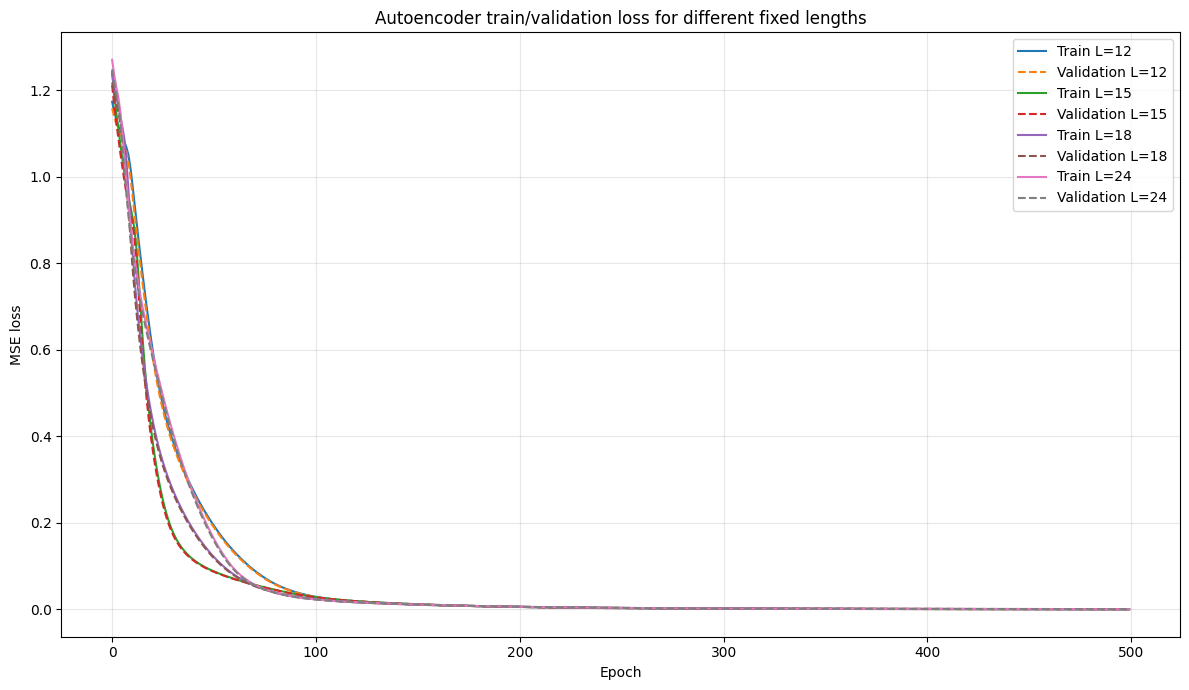

In [131]:
plt.figure(figsize=(12, 7))

for result in results:

    L = result["fixed_len"]
    h = result["history"]

    plt.plot(
        h["loss"],
        label=f"Train L={L}"
    )

    plt.plot(
        h["val_loss"],
        linestyle="--",
        label=f"Validation L={L}"
    )

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Autoencoder train/validation loss for different fixed lengths")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Total DD: 1747
Total trips: 234
Usable DD: (1724, 12)
Usable trips: (172, 12)

SEED / SHUFFLE: 10
AE train: (1016, 12)
AE validation: (345, 12)
DD test pool: (345, 12)
AE epochs: 500
Best AE validation loss: 0.000627692264970392
Trip development: 86
Trip final test: 86
Best threshold: 0.598989898989899
Validation F1: 0.9019607843137255

FINAL TEST
F1: 0.7857142857142857
Precision: 0.8048780487804879
Recall: 0.7674418604651163
ROC AUC: 0.8731070849107625
PR AUC: 0.8908204281508721
Confusion matrix:
[[70 16]
 [20 66]]

TRUE POSITIVES


,seed,cavity,original_index,prob_trip
93,10,HBL-010RFC:RFS-DIG-101,1,0.989441
132,10,HBL-010RFC:RFS-DIG-101,20,0.989441
130,10,HBL-010RFC:RFS-DIG-101,32,0.989441
23,10,HBL-010RFC:RFS-DIG-101,36,0.989441
113,10,HBL-010RFC:RFS-DIG-101,47,0.989441
...,...,...,...,...
96,10,HBL-010RFC:RFS-DIG-401,149,0.878354
164,10,HBL-010RFC:RFS-DIG-401,153,0.878354
116,10,HBL-010RFC:RFS-DIG-401,181,0.860965
44,10,HBL-010RFC:RFS-DIG-401,191,0.905573



FALSE POSITIVES


,seed,cavity,original_index,prob_trip
43,10,HBL-010RFC:RFS-DIG-101,18,0.989441
71,10,HBL-010RFC:RFS-DIG-101,936,0.777904
154,10,HBL-010RFC:RFS-DIG-101,1004,0.824232
42,10,HBL-010RFC:RFS-DIG-201,660,0.698881
5,10,HBL-010RFC:RFS-DIG-201,1151,0.610005
59,10,HBL-010RFC:RFS-DIG-201,1309,0.689191
138,10,HBL-010RFC:RFS-DIG-201,1358,0.732254
2,10,HBL-010RFC:RFS-DIG-201,1439,0.704632
64,10,HBL-010RFC:RFS-DIG-301,705,0.749561
161,10,HBL-010RFC:RFS-DIG-301,712,0.702475



SEED / SHUFFLE: 20
AE train: (1018, 12)
AE validation: (345, 12)
DD test pool: (345, 12)
AE epochs: 500
Best AE validation loss: 0.0033450210466980934
Trip development: 86
Trip final test: 86
Best threshold: 0.24757575757575756
Validation F1: 0.75

FINAL TEST
F1: 0.7564766839378239
Precision: 0.6822429906542056
Recall: 0.8488372093023255
ROC AUC: 0.8557328285559762
PR AUC: 0.8714424261201508
Confusion matrix:
[[52 34]
 [13 73]]

TRUE POSITIVES


...


TP PER CAVITY


,cavity,TP_count
0,HBL-010RFC:RFS-DIG-101,112
1,HBL-010RFC:RFS-DIG-201,48
2,HBL-010RFC:RFS-DIG-301,39
3,HBL-010RFC:RFS-DIG-401,115



FP PER CAVITY


,cavity,FP_count
0,HBL-010RFC:RFS-DIG-101,17
1,HBL-010RFC:RFS-DIG-201,24
2,HBL-010RFC:RFS-DIG-301,22
3,HBL-010RFC:RFS-DIG-401,28



5 SHUFFLES — MEAN ± STD
test_f1        : 0.7484 ± 0.0347
precision      : 0.8096 ± 0.1256
recall         : 0.7302 ± 0.1474
roc_auc        : 0.8446 ± 0.0299
pr_auc         : 0.8725 ± 0.0177


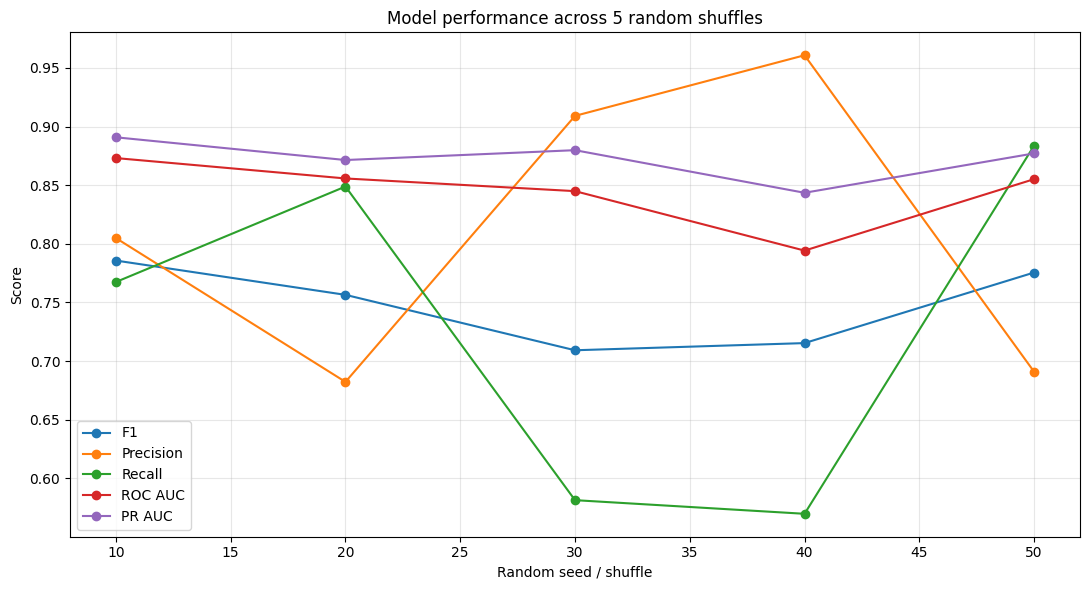

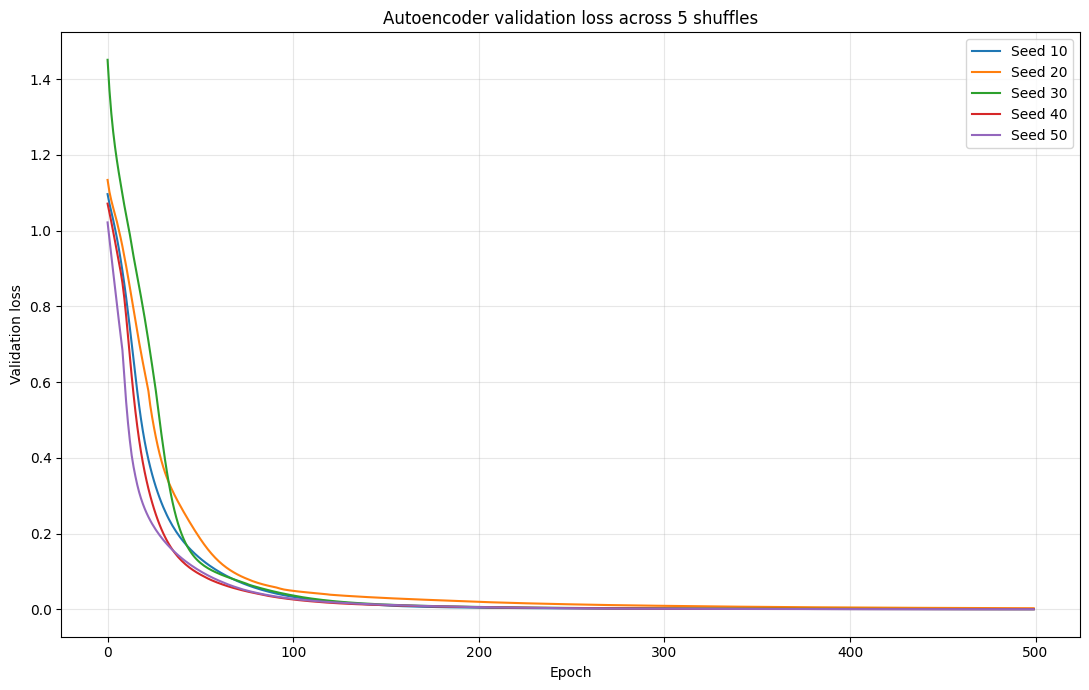

In [140]:
# ============================================================
# COMPLETE MODEL
# 4 CAVITIES MIXED + 5 SHUFFLES
# WITH TP / FP CAVITY + ORIGINAL INDEX
# ============================================================

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

from xgboost import XGBClassifier


# ============================================================
# SETTINGS
# ============================================================

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

FIXED_LEN = 12
EPOCHS = 500
BATCH_SIZE = 16
PATIENCE = 20
WINDOW_SIZE = 6

SEEDS = [10, 20, 30, 40, 50]

FEATURE_COLUMNS = [
    "res_mean",
    "res_std",
    "res_max_minus_min",
    "res_mae",
    "res_mse",
    "res_max_abs"
]


# ============================================================
# VALUE COLUMNS
# ============================================================

value_columns = [c for c in dataset.columns if c.startswith("value_")]


# ============================================================
# DATA
# ============================================================

dd_all = dataset[
    (dataset["label"] == 0) &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

trip_all = dataset[
    (dataset["label"] == 1) &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

print("Total DD:", len(dd_all))
print("Total trips:", len(trip_all))


# ============================================================
# PLATEAU FUNCTIONS
# ============================================================

def get_flat_plateau(y, slope_threshold=0.1, amp_min=18, amp_max=24):
    y = np.asarray(y, dtype=float)
    slope = np.diff(y)

    flat_mask = np.zeros(len(y), dtype=bool)
    flat_mask[1:] = np.abs(slope) <= slope_threshold
    flat_mask &= (y >= amp_min) & (y <= amp_max)

    segments = []
    start = None

    for i, flag in enumerate(flat_mask):
        if flag and start is None:
            start = i
        elif not flag and start is not None:
            segments.append((start, i))
            start = None

    if start is not None:
        segments.append((start, len(y)))

    if not segments:
        return None

    return max(segments, key=lambda s: s[1] - s[0])


def resample_plateau(flat, fixed_len):
    flat = np.asarray(flat, dtype=float)
    x_old = np.linspace(0, 1, len(flat))
    x_new = np.linspace(0, 1, fixed_len)
    return np.interp(x_new, x_old, flat)


def extract_fixed_plateau(row, fixed_len=FIXED_LEN):
    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau
    flat = y[start:end]

    if len(flat) < 6:
        return None

    return resample_plateau(flat, fixed_len)


# ============================================================
# DD OUTLIER FEATURE
# ============================================================

def mean_window_range(row):
    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return np.nan

    start, end = plateau
    flat = y[start:end]

    window_ranges = []

    for j in range(0, len(flat) - WINDOW_SIZE + 1, WINDOW_SIZE):
        window = flat[j:j + WINDOW_SIZE]
        window_ranges.append(window.max() - window.min())

    if len(window_ranges) == 0:
        return np.nan

    return np.mean(window_ranges)


def remove_training_dd_outliers(df):
    df = df.copy()

    df["mean_window_range"] = [
        mean_window_range(row)
        for _, row in df.iterrows()
    ]

    cleaned = []

    for cavity in df["cavity"].unique():
        temp = df[df["cavity"] == cavity].copy()
        values = temp["mean_window_range"].dropna()

        if len(values) == 0:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        upper_bound = q3 + 1.5 * iqr

        temp = temp[temp["mean_window_range"] <= upper_bound]
        cleaned.append(temp)

    if len(cleaned) == 0:
        return pd.DataFrame(columns=df.columns)

    return pd.concat(cleaned, ignore_index=True)


# ============================================================
# DATAFRAME -> PLATEAUX
# ============================================================

def dataframe_to_plateaux(df, fixed_len=FIXED_LEN):
    vectors = []
    metadata = []

    for idx, row in df.iterrows():
        plateau = extract_fixed_plateau(row, fixed_len=fixed_len)

        if plateau is not None:
            vectors.append(plateau)
            metadata.append({
                "index": idx,
                "cavity": row["cavity"]
            })

    if len(vectors) == 0:
        return (
            np.empty((0, fixed_len)),
            pd.DataFrame(columns=["index", "cavity"])
        )

    return np.vstack(vectors), pd.DataFrame(metadata)


# ============================================================
# AUTOENCODER
# ============================================================

def build_autoencoder(input_dim):
    input_layer = Input(shape=(input_dim,))

    encoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(input_layer)

    latent = Dense(4)(encoder)
    latent = LeakyReLU(negative_slope=0.075)(latent)

    decoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(latent)

    output_layer = Dense(input_dim)(decoder)

    model = Model(input_layer, output_layer)

    model.compile(
        loss="mean_squared_error",
        optimizer=Adam(learning_rate=1e-4)
    )

    return model


# ============================================================
# RESIDUAL FEATURES
# ============================================================

def residual_features(residual):
    return pd.DataFrame({
        "res_mean": residual.mean(axis=1),
        "res_std": residual.std(axis=1),
        "res_max_minus_min": residual.max(axis=1) - residual.min(axis=1),
        "res_mae": np.mean(np.abs(residual), axis=1),
        "res_mse": np.mean(residual**2, axis=1),
        "res_max_abs": np.max(np.abs(residual), axis=1)
    })


# ============================================================
# PRE-EXTRACT DD
# ============================================================

dd_vectors = []
dd_metadata = []

for idx, row in dd_all.iterrows():
    flat_fixed = extract_fixed_plateau(row, FIXED_LEN)

    if flat_fixed is not None:
        dd_vectors.append(flat_fixed)
        dd_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })

X_dd_all = np.vstack(dd_vectors)
dd_metadata = pd.DataFrame(dd_metadata)

print("Usable DD:", X_dd_all.shape)


# ============================================================
# PRE-EXTRACT TRIPS
# ============================================================

trip_vectors = []
trip_metadata = []

for idx, row in trip_all.iterrows():
    flat_fixed = extract_fixed_plateau(row, FIXED_LEN)

    if flat_fixed is not None:
        trip_vectors.append(flat_fixed)
        trip_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })

X_trip_all = np.vstack(trip_vectors)
trip_metadata = pd.DataFrame(trip_metadata)

print("Usable trips:", X_trip_all.shape)


# ============================================================
# DD MATCHING FUNCTION
# ============================================================

def sample_matching_dd_indices(metadata, trip_meta, random_state):
    selected = []
    rng = np.random.RandomState(random_state)

    for cavity_name, n_needed in trip_meta["cavity"].value_counts().items():
        available = metadata[
            metadata["cavity"] == cavity_name
        ].index.to_numpy()

        if len(available) < n_needed:
            raise ValueError(
                f"{cavity_name}: need {n_needed} DD, have {len(available)}"
            )

        chosen = rng.choice(
            available,
            size=n_needed,
            replace=False
        )

        selected.extend(chosen.tolist())

    return np.array(selected, dtype=int)


# ============================================================
# STORAGE
# ============================================================

all_results = []
all_histories = {}
all_test_predictions = []


# ============================================================
# 5 SHUFFLES
# ============================================================

for seed in SEEDS:

    print("\n" + "=" * 80)
    print("SEED / SHUFFLE:", seed)
    print("=" * 80)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


    # ========================================================
    # DD SPLIT 60 / 20 / 20
    # ========================================================

    dd_indices = np.arange(len(X_dd_all))

    idx_dd_train, idx_dd_temp = train_test_split(
        dd_indices,
        test_size=0.40,
        random_state=seed,
        stratify=dd_metadata["cavity"]
    )

    idx_dd_val, idx_dd_test = train_test_split(
        idx_dd_temp,
        test_size=0.50,
        random_state=seed,
        stratify=dd_metadata.iloc[idx_dd_temp]["cavity"]
    )


    # ========================================================
    # CLEAN AE TRAIN DD ONLY
    # ========================================================

    dd_train_original_indices = (
        dd_metadata
        .iloc[idx_dd_train]["original_index"]
        .to_numpy()
    )

    dd_train_df = dd_all.iloc[
        dd_train_original_indices
    ].copy()

    dd_train_clean = remove_training_dd_outliers(dd_train_df)

    X_train, _ = dataframe_to_plateaux(
        dd_train_clean,
        FIXED_LEN
    )

    X_val = X_dd_all[idx_dd_val]
    X_test_dd = X_dd_all[idx_dd_test]

    meta_val = (
        dd_metadata
        .iloc[idx_dd_val]
        .reset_index(drop=True)
    )

    meta_test = (
        dd_metadata
        .iloc[idx_dd_test]
        .reset_index(drop=True)
    )

    print("AE train:", X_train.shape)
    print("AE validation:", X_val.shape)
    print("DD test pool:", X_test_dd.shape)


    # ========================================================
    # SCALER
    # ========================================================

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_dd_scaled = scaler.transform(X_test_dd)


    # ========================================================
    # AUTOENCODER
    # ========================================================

    K.clear_session()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    ae = build_autoencoder(FIXED_LEN)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = ae.fit(
        X_train_scaled,
        X_train_scaled,
        validation_data=(X_val_scaled, X_val_scaled),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
        callbacks=[early_stop]
    )

    all_histories[seed] = history.history

    print("AE epochs:", len(history.history["loss"]))
    print("Best AE validation loss:", min(history.history["val_loss"]))


    # ========================================================
    # DD RESIDUAL FEATURES
    # ========================================================

    X_val_rec = ae.predict(X_val_scaled, verbose=0)
    X_test_dd_rec = ae.predict(X_test_dd_scaled, verbose=0)

    res_dd_val = X_val_scaled - X_val_rec
    res_dd_test = X_test_dd_scaled - X_test_dd_rec

    features_dd_val = residual_features(res_dd_val).reset_index(drop=True)
    features_dd_test = residual_features(res_dd_test).reset_index(drop=True)


    # ========================================================
    # TRIP SPLIT 50 / 50
    # ========================================================

    trip_indices = np.arange(len(X_trip_all))

    idx_trip_dev, idx_trip_test = train_test_split(
        trip_indices,
        test_size=0.50,
        random_state=seed,
        stratify=trip_metadata["cavity"]
    )

    X_trip_dev = X_trip_all[idx_trip_dev]
    X_trip_test = X_trip_all[idx_trip_test]

    trip_meta_dev = (
        trip_metadata
        .iloc[idx_trip_dev]
        .reset_index(drop=True)
    )

    trip_meta_test = (
        trip_metadata
        .iloc[idx_trip_test]
        .reset_index(drop=True)
    )

    print("Trip development:", len(X_trip_dev))
    print("Trip final test:", len(X_trip_test))


    # ========================================================
    # TRIP RESIDUAL FEATURES
    # ========================================================

    X_trip_dev_scaled = scaler.transform(X_trip_dev)
    X_trip_test_scaled = scaler.transform(X_trip_test)

    X_trip_dev_rec = ae.predict(X_trip_dev_scaled, verbose=0)
    X_trip_test_rec = ae.predict(X_trip_test_scaled, verbose=0)

    res_trip_dev = X_trip_dev_scaled - X_trip_dev_rec
    res_trip_test = X_trip_test_scaled - X_trip_test_rec

    features_trip_dev = residual_features(res_trip_dev)
    features_trip_test = residual_features(res_trip_test)


    # ========================================================
    # BALANCE DD DEVELOPMENT + TEST BY CAVITY
    # ========================================================

    idx_dd_dev_bal = sample_matching_dd_indices(
        meta_val,
        trip_meta_dev,
        seed
    )

    idx_dd_test_bal = sample_matching_dd_indices(
        meta_test,
        trip_meta_test,
        seed + 100
    )

    features_dd_dev_bal = (
        features_dd_val
        .iloc[idx_dd_dev_bal]
        .reset_index(drop=True)
    )

    features_dd_test_bal = (
        features_dd_test
        .iloc[idx_dd_test_bal]
        .reset_index(drop=True)
    )

    meta_dd_test_bal = (
        meta_test
        .iloc[idx_dd_test_bal]
        .reset_index(drop=True)
    )


    # ========================================================
    # CLASSIFIER DEVELOPMENT
    # ========================================================

    dd_clf = features_dd_dev_bal.copy()
    dd_clf["label"] = 0

    trip_clf = features_trip_dev.copy()
    trip_clf["label"] = 1

    classifier_pool = pd.concat(
        [dd_clf, trip_clf],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    X_clf = classifier_pool[FEATURE_COLUMNS]
    y_clf = classifier_pool["label"]


    # ========================================================
    # XGBOOST TRAIN / THRESHOLD VALIDATION
    # ========================================================

    X_xgb_train, X_threshold_val, y_xgb_train, y_threshold_val = train_test_split(
        X_clf,
        y_clf,
        test_size=0.30,
        random_state=seed,
        stratify=y_clf
    )

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=seed,
        n_jobs=-1
    )

    xgb.fit(
        X_xgb_train,
        y_xgb_train
    )


    # ========================================================
    # BEST THRESHOLD
    # ========================================================

    val_prob = xgb.predict_proba(
        X_threshold_val
    )[:, 1]

    thresholds = np.linspace(
        0.01,
        0.99,
        199
    )

    f1_scores = []

    for threshold in thresholds:
        val_pred = (val_prob >= threshold).astype(int)
        f1_scores.append(
            f1_score(
                y_threshold_val,
                val_pred
            )
        )

    best_index = np.argmax(f1_scores)
    best_threshold = thresholds[best_index]
    validation_f1 = f1_scores[best_index]

    print("Best threshold:", best_threshold)
    print("Validation F1:", validation_f1)


    # ========================================================
    # FINAL TEST WITH METADATA
    # ========================================================

    dd_final = features_dd_test_bal.copy()
    dd_final["label"] = 0
    dd_final["cavity"] = meta_dd_test_bal["cavity"].to_numpy()
    dd_final["original_index"] = meta_dd_test_bal["original_index"].to_numpy()
    dd_final["source"] = "DD"

    trip_final = features_trip_test.copy()
    trip_final["label"] = 1
    trip_final["cavity"] = trip_meta_test["cavity"].to_numpy()
    trip_final["original_index"] = trip_meta_test["original_index"].to_numpy()
    trip_final["source"] = "Trip"

    final_test = pd.concat(
        [dd_final, trip_final],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    X_final = final_test[FEATURE_COLUMNS]
    y_final = final_test["label"]


    # ========================================================
    # FINAL PREDICTION
    # ========================================================

    test_prob = xgb.predict_proba(
        X_final
    )[:, 1]

    y_pred = (
        test_prob >= best_threshold
    ).astype(int)

    final_test["prob_trip"] = test_prob
    final_test["predicted_label"] = y_pred
    final_test["seed"] = seed


    # ========================================================
    # TP / FP / TN / FN
    # ========================================================

    final_test["classification"] = np.select(
        [
            (final_test["label"] == 1) & (final_test["predicted_label"] == 1),
            (final_test["label"] == 0) & (final_test["predicted_label"] == 1),
            (final_test["label"] == 0) & (final_test["predicted_label"] == 0),
            (final_test["label"] == 1) & (final_test["predicted_label"] == 0)
        ],
        ["TP", "FP", "TN", "FN"],
        default="Unknown"
    )

    all_test_predictions.append(
        final_test.copy()
    )


    # ========================================================
    # METRICS
    # ========================================================

    test_f1 = f1_score(y_final, y_pred)

    precision = precision_score(
        y_final,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_final,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_final,
        test_prob
    )

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_final,
        test_prob
    )

    pr_auc = auc(
        recall_curve,
        precision_curve
    )

    cm = confusion_matrix(
        y_final,
        y_pred
    )

    print("\nFINAL TEST")
    print("F1:", test_f1)
    print("Precision:", precision)
    print("Recall:", recall)
    print("ROC AUC:", roc_auc)
    print("PR AUC:", pr_auc)
    print("Confusion matrix:")
    print(cm)


    # ========================================================
    # TP / FP FOR CURRENT SEED
    # ========================================================

    tp_seed = final_test[
        final_test["classification"] == "TP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ].sort_values(
        ["cavity", "original_index"]
    )

    fp_seed = final_test[
        final_test["classification"] == "FP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ].sort_values(
        ["cavity", "original_index"]
    )

    print("\nTRUE POSITIVES")
    display(tp_seed)

    print("\nFALSE POSITIVES")
    display(fp_seed)


    # ========================================================
    # SAVE METRICS
    # ========================================================

    all_results.append({
        "seed": seed,
        "ae_train": len(X_train),
        "ae_val": len(X_val),
        "trip_dev": len(X_trip_dev),
        "trip_test": len(X_trip_test),
        "best_threshold": best_threshold,
        "validation_f1": validation_f1,
        "test_f1": test_f1,
        "precision": precision,
        "recall": recall,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "ae_epochs": len(history.history["loss"]),
        "ae_best_val_loss": min(history.history["val_loss"])
    })


# ============================================================
# RESULTS TABLE
# ============================================================

results_shuffle = pd.DataFrame(
    all_results
)

display(
    results_shuffle
)


# ============================================================
# ALL TEST PREDICTIONS
# ============================================================

all_test_predictions_df = pd.concat(
    all_test_predictions,
    ignore_index=True
)


# ============================================================
# ALL TRUE POSITIVES
# ============================================================

all_tp = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "TP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ]
    .sort_values(
        ["seed", "cavity", "original_index"]
    )
    .reset_index(drop=True)
)

print("\nALL TRUE POSITIVES")
display(all_tp)


# ============================================================
# ALL FALSE POSITIVES
# ============================================================

all_fp = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "FP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ]
    .sort_values(
        ["seed", "cavity", "original_index"]
    )
    .reset_index(drop=True)
)

print("\nALL FALSE POSITIVES")
display(all_fp)


# ============================================================
# TP COUNT PER CAVITY
# ============================================================

tp_per_cavity = (
    all_tp
    .groupby("cavity")
    .size()
    .rename("TP_count")
    .reset_index()
)

print("\nTP PER CAVITY")
display(tp_per_cavity)


# ============================================================
# FP COUNT PER CAVITY
# ============================================================

fp_per_cavity = (
    all_fp
    .groupby("cavity")
    .size()
    .rename("FP_count")
    .reset_index()
)

print("\nFP PER CAVITY")
display(fp_per_cavity)


# ============================================================
# MEAN ± STD ACROSS 5 SHUFFLES
# ============================================================

metrics = [
    "test_f1",
    "precision",
    "recall",
    "roc_auc",
    "pr_auc"
]

print("\n" + "=" * 60)
print("5 SHUFFLES — MEAN ± STD")
print("=" * 60)

for metric in metrics:
    print(
        f"{metric:15s}: "
        f"{results_shuffle[metric].mean():.4f} "
        f"± "
        f"{results_shuffle[metric].std():.4f}"
    )


# ============================================================
# PERFORMANCE ACROSS SHUFFLES
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(results_shuffle["seed"], results_shuffle["test_f1"], marker="o", label="F1")
plt.plot(results_shuffle["seed"], results_shuffle["precision"], marker="o", label="Precision")
plt.plot(results_shuffle["seed"], results_shuffle["recall"], marker="o", label="Recall")
plt.plot(results_shuffle["seed"], results_shuffle["roc_auc"], marker="o", label="ROC AUC")
plt.plot(results_shuffle["seed"], results_shuffle["pr_auc"], marker="o", label="PR AUC")

plt.xlabel("Random seed / shuffle")
plt.ylabel("Score")
plt.title("Model performance across 5 random shuffles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# AE VALIDATION LOSS
# ============================================================

plt.figure(figsize=(11, 7))

for seed, history in all_histories.items():
    plt.plot(history["val_loss"], label=f"Seed {seed}")

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Autoencoder validation loss across 5 shuffles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Total DD: 1747
Total trips: 234
Usable DD: (1724, 15)
Usable trips: (172, 15)

SEED / SHUFFLE: 10
AE train: (1016, 15)
AE validation: (345, 15)
DD test pool: (345, 15)
AE epochs: 500
Best AE validation loss: 0.0010344624752178788
Trip development: 86
Trip final test: 86
Best threshold: 0.7672727272727272
Validation F1: 0.8444444444444444

FINAL TEST
F1: 0.7397260273972602
Precision: 0.9
Recall: 0.627906976744186
ROC AUC: 0.8554624121146566
PR AUC: 0.8835471790948757
Confusion matrix:
[[80  6]
 [32 54]]

TRUE POSITIVES


,seed,cavity,original_index,prob_trip
93,10,HBL-010RFC:RFS-DIG-101,1,0.983871
132,10,HBL-010RFC:RFS-DIG-101,20,0.983871
130,10,HBL-010RFC:RFS-DIG-101,32,0.983871
23,10,HBL-010RFC:RFS-DIG-101,36,0.983871
113,10,HBL-010RFC:RFS-DIG-101,47,0.983871
114,10,HBL-010RFC:RFS-DIG-101,54,0.983871
109,10,HBL-010RFC:RFS-DIG-101,56,0.983871
3,10,HBL-010RFC:RFS-DIG-101,60,0.983871
103,10,HBL-010RFC:RFS-DIG-101,64,0.983871
156,10,HBL-010RFC:RFS-DIG-101,79,0.983871



FALSE POSITIVES


,seed,cavity,original_index,prob_trip
43,10,HBL-010RFC:RFS-DIG-101,18,0.983871
2,10,HBL-010RFC:RFS-DIG-201,1439,0.921626
35,10,HBL-010RFC:RFS-DIG-201,1570,0.778469
146,10,HBL-010RFC:RFS-DIG-301,835,0.917076
15,10,HBL-010RFC:RFS-DIG-401,667,0.903714
99,10,HBL-010RFC:RFS-DIG-401,686,0.945626



SEED / SHUFFLE: 20
AE train: (1018, 15)
AE validation: (345, 15)
DD test pool: (345, 15)
AE epochs: 500
Best AE validation loss: 0.0030792965553700924
Trip development: 86
Trip final test: 86
Best threshold: 0.7078787878787879
Validation F1: 0.7272727272727273

FINAL TEST
F1: 0.7862068965517242
Precision: 0.9661016949152542
Recall: 0.6627906976744186
ROC AUC: 0.8595862628447809
PR AUC: 0.8971939737193267
Confusion matrix:
[[84  2]
 [29 57]]

TRUE POSITIVES


...


TP PER CAVITY


,cavity,TP_count
0,HBL-010RFC:RFS-DIG-101,102
1,HBL-010RFC:RFS-DIG-201,32
2,HBL-010RFC:RFS-DIG-301,40
3,HBL-010RFC:RFS-DIG-401,108



FP PER CAVITY


,cavity,FP_count
0,HBL-010RFC:RFS-DIG-101,4
1,HBL-010RFC:RFS-DIG-201,10
2,HBL-010RFC:RFS-DIG-301,8
3,HBL-010RFC:RFS-DIG-401,21



5 SHUFFLES — MEAN ± STD
test_f1        : 0.7447 ± 0.0469
precision      : 0.8811 ± 0.0790
recall         : 0.6558 ± 0.0961
roc_auc        : 0.8475 ± 0.0295
pr_auc         : 0.8804 ± 0.0237


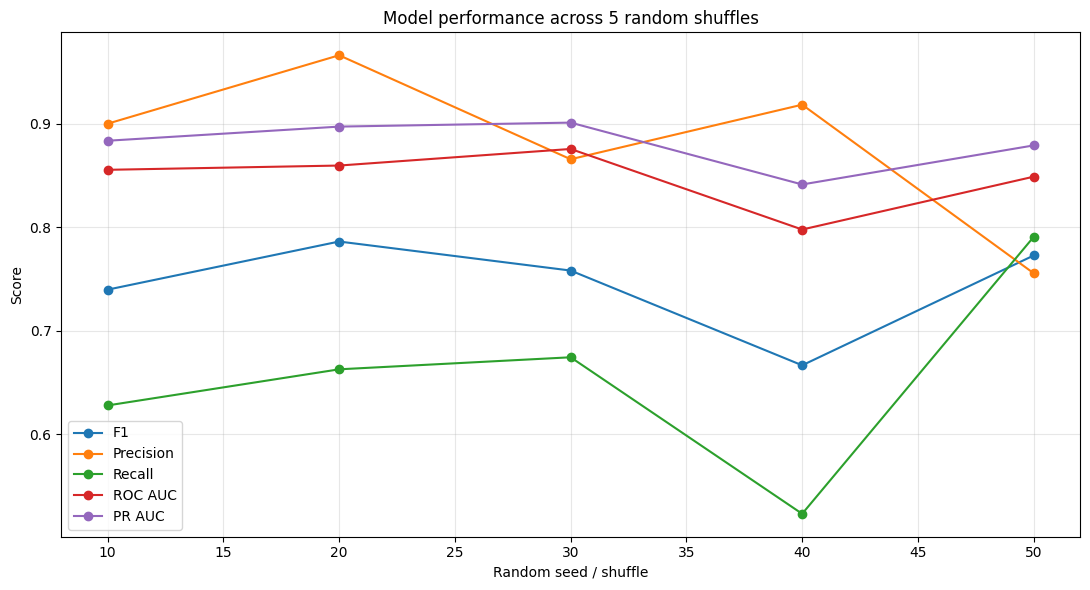

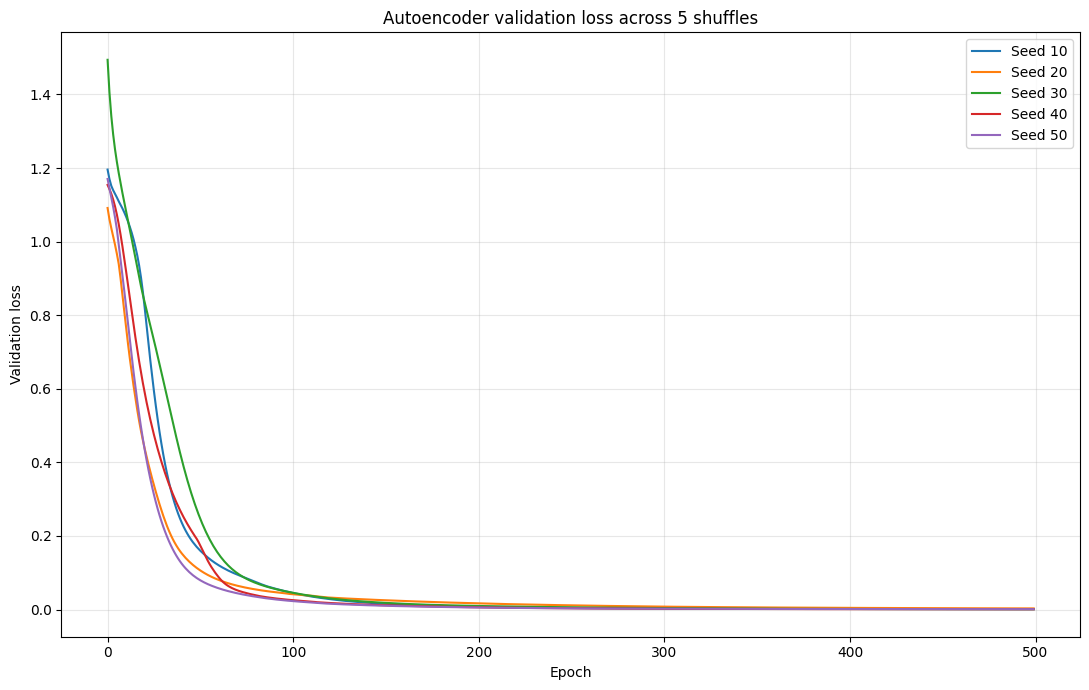

In [153]:
# ============================================================
# COMPLETE MODEL
# 4 CAVITIES MIXED + 5 SHUFFLES
# WITH TP / FP CAVITY + ORIGINAL INDEX
# ============================================================

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix
)

from xgboost import XGBClassifier


# ============================================================
# SETTINGS
# ============================================================

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

FIXED_LEN = 15
EPOCHS = 500
BATCH_SIZE = 16
PATIENCE = 20
WINDOW_SIZE = 6

SEEDS = [10, 20, 30, 40, 50]

FEATURE_COLUMNS = [
    "res_mean",
    "res_std",
    "res_max_minus_min",
    "res_mae",
    "res_mse",
    "res_max_abs"
]


# ============================================================
# VALUE COLUMNS
# ============================================================

value_columns = [c for c in dataset.columns if c.startswith("value_")]


# ============================================================
# DATA
# ============================================================

dd_all = dataset[
    (dataset["label"] == 0) &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

trip_all = dataset[
    (dataset["label"] == 1) &
    (dataset["cavity"].isin(cavity_names))
].copy().reset_index(drop=True)

print("Total DD:", len(dd_all))
print("Total trips:", len(trip_all))


# ============================================================
# PLATEAU FUNCTIONS
# ============================================================

def get_flat_plateau(y, slope_threshold=0.1, amp_min=18, amp_max=24):
    y = np.asarray(y, dtype=float)
    slope = np.diff(y)

    flat_mask = np.zeros(len(y), dtype=bool)
    flat_mask[1:] = np.abs(slope) <= slope_threshold
    flat_mask &= (y >= amp_min) & (y <= amp_max)

    segments = []
    start = None

    for i, flag in enumerate(flat_mask):
        if flag and start is None:
            start = i
        elif not flag and start is not None:
            segments.append((start, i))
            start = None

    if start is not None:
        segments.append((start, len(y)))

    if not segments:
        return None

    return max(segments, key=lambda s: s[1] - s[0])


def resample_plateau(flat, fixed_len):
    flat = np.asarray(flat, dtype=float)
    x_old = np.linspace(0, 1, len(flat))
    x_new = np.linspace(0, 1, fixed_len)
    return np.interp(x_new, x_old, flat)


def extract_fixed_plateau(row, fixed_len=FIXED_LEN):
    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start, end = plateau
    flat = y[start:end]

    if len(flat) < 6:
        return None

    return resample_plateau(flat, fixed_len)


# ============================================================
# DD OUTLIER FEATURE
# ============================================================

def mean_window_range(row):
    y = row[value_columns].to_numpy(dtype=float)

    plateau = get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return np.nan

    start, end = plateau
    flat = y[start:end]

    window_ranges = []

    for j in range(0, len(flat) - WINDOW_SIZE + 1, WINDOW_SIZE):
        window = flat[j:j + WINDOW_SIZE]
        window_ranges.append(window.max() - window.min())

    if len(window_ranges) == 0:
        return np.nan

    return np.mean(window_ranges)


def remove_training_dd_outliers(df):
    df = df.copy()

    df["mean_window_range"] = [
        mean_window_range(row)
        for _, row in df.iterrows()
    ]

    cleaned = []

    for cavity in df["cavity"].unique():
        temp = df[df["cavity"] == cavity].copy()
        values = temp["mean_window_range"].dropna()

        if len(values) == 0:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        upper_bound = q3 + 1.5 * iqr

        temp = temp[temp["mean_window_range"] <= upper_bound]
        cleaned.append(temp)

    if len(cleaned) == 0:
        return pd.DataFrame(columns=df.columns)

    return pd.concat(cleaned, ignore_index=True)


# ============================================================
# DATAFRAME -> PLATEAUX
# ============================================================

def dataframe_to_plateaux(df, fixed_len=FIXED_LEN):
    vectors = []
    metadata = []

    for idx, row in df.iterrows():
        plateau = extract_fixed_plateau(row, fixed_len=fixed_len)

        if plateau is not None:
            vectors.append(plateau)
            metadata.append({
                "index": idx,
                "cavity": row["cavity"]
            })

    if len(vectors) == 0:
        return (
            np.empty((0, fixed_len)),
            pd.DataFrame(columns=["index", "cavity"])
        )

    return np.vstack(vectors), pd.DataFrame(metadata)


# ============================================================
# AUTOENCODER
# ============================================================

def build_autoencoder(input_dim):
    input_layer = Input(shape=(input_dim,))

    encoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(input_layer)

    latent = Dense(4)(encoder)
    latent = LeakyReLU(negative_slope=0.075)(latent)

    decoder = Dense(
        8,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.01)
    )(latent)

    output_layer = Dense(input_dim)(decoder)

    model = Model(input_layer, output_layer)

    model.compile(
        loss="mean_squared_error",
        optimizer=Adam(learning_rate=1e-4)
    )

    return model


# ============================================================
# RESIDUAL FEATURES
# ============================================================

def residual_features(residual):
    return pd.DataFrame({
        "res_mean": residual.mean(axis=1),
        "res_std": residual.std(axis=1),
        "res_max_minus_min": residual.max(axis=1) - residual.min(axis=1),
        "res_mae": np.mean(np.abs(residual), axis=1),
        "res_mse": np.mean(residual**2, axis=1),
        "res_max_abs": np.max(np.abs(residual), axis=1)
    })


# ============================================================
# PRE-EXTRACT DD
# ============================================================

dd_vectors = []
dd_metadata = []

for idx, row in dd_all.iterrows():
    flat_fixed = extract_fixed_plateau(row, FIXED_LEN)

    if flat_fixed is not None:
        dd_vectors.append(flat_fixed)
        dd_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })

X_dd_all = np.vstack(dd_vectors)
dd_metadata = pd.DataFrame(dd_metadata)

print("Usable DD:", X_dd_all.shape)


# ============================================================
# PRE-EXTRACT TRIPS
# ============================================================

trip_vectors = []
trip_metadata = []

for idx, row in trip_all.iterrows():
    flat_fixed = extract_fixed_plateau(row, FIXED_LEN)

    if flat_fixed is not None:
        trip_vectors.append(flat_fixed)
        trip_metadata.append({
            "original_index": idx,
            "cavity": row["cavity"]
        })

X_trip_all = np.vstack(trip_vectors)
trip_metadata = pd.DataFrame(trip_metadata)

print("Usable trips:", X_trip_all.shape)


# ============================================================
# DD MATCHING FUNCTION
# ============================================================

def sample_matching_dd_indices(metadata, trip_meta, random_state):
    selected = []
    rng = np.random.RandomState(random_state)

    for cavity_name, n_needed in trip_meta["cavity"].value_counts().items():
        available = metadata[
            metadata["cavity"] == cavity_name
        ].index.to_numpy()

        if len(available) < n_needed:
            raise ValueError(
                f"{cavity_name}: need {n_needed} DD, have {len(available)}"
            )

        chosen = rng.choice(
            available,
            size=n_needed,
            replace=False
        )

        selected.extend(chosen.tolist())

    return np.array(selected, dtype=int)


# ============================================================
# STORAGE
# ============================================================

all_results = []
all_histories = {}
all_test_predictions = []


# ============================================================
# 5 SHUFFLES
# ============================================================

for seed in SEEDS:

    print("\n" + "=" * 80)
    print("SEED / SHUFFLE:", seed)
    print("=" * 80)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


    # ========================================================
    # DD SPLIT 60 / 20 / 20
    # ========================================================

    dd_indices = np.arange(len(X_dd_all))

    idx_dd_train, idx_dd_temp = train_test_split(
        dd_indices,
        test_size=0.40,
        random_state=seed,
        stratify=dd_metadata["cavity"]
    )

    idx_dd_val, idx_dd_test = train_test_split(
        idx_dd_temp,
        test_size=0.50,
        random_state=seed,
        stratify=dd_metadata.iloc[idx_dd_temp]["cavity"]
    )


    # ========================================================
    # CLEAN AE TRAIN DD ONLY
    # ========================================================

    dd_train_original_indices = (
        dd_metadata
        .iloc[idx_dd_train]["original_index"]
        .to_numpy()
    )

    dd_train_df = dd_all.iloc[
        dd_train_original_indices
    ].copy()

    dd_train_clean = remove_training_dd_outliers(dd_train_df)

    X_train, _ = dataframe_to_plateaux(
        dd_train_clean,
        FIXED_LEN
    )

    X_val = X_dd_all[idx_dd_val]
    X_test_dd = X_dd_all[idx_dd_test]

    meta_val = (
        dd_metadata
        .iloc[idx_dd_val]
        .reset_index(drop=True)
    )

    meta_test = (
        dd_metadata
        .iloc[idx_dd_test]
        .reset_index(drop=True)
    )

    print("AE train:", X_train.shape)
    print("AE validation:", X_val.shape)
    print("DD test pool:", X_test_dd.shape)


    # ========================================================
    # SCALER
    # ========================================================

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_dd_scaled = scaler.transform(X_test_dd)


    # ========================================================
    # AUTOENCODER
    # ========================================================

    K.clear_session()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    ae = build_autoencoder(FIXED_LEN)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = ae.fit(
        X_train_scaled,
        X_train_scaled,
        validation_data=(X_val_scaled, X_val_scaled),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
        callbacks=[early_stop]
    )

    all_histories[seed] = history.history

    print("AE epochs:", len(history.history["loss"]))
    print("Best AE validation loss:", min(history.history["val_loss"]))


    # ========================================================
    # DD RESIDUAL FEATURES
    # ========================================================

    X_val_rec = ae.predict(X_val_scaled, verbose=0)
    X_test_dd_rec = ae.predict(X_test_dd_scaled, verbose=0)

    res_dd_val = X_val_scaled - X_val_rec
    res_dd_test = X_test_dd_scaled - X_test_dd_rec

    features_dd_val = residual_features(res_dd_val).reset_index(drop=True)
    features_dd_test = residual_features(res_dd_test).reset_index(drop=True)


    # ========================================================
    # TRIP SPLIT 50 / 50
    # ========================================================

    trip_indices = np.arange(len(X_trip_all))

    idx_trip_dev, idx_trip_test = train_test_split(
        trip_indices,
        test_size=0.50,
        random_state=seed,
        stratify=trip_metadata["cavity"]
    )

    X_trip_dev = X_trip_all[idx_trip_dev]
    X_trip_test = X_trip_all[idx_trip_test]

    trip_meta_dev = (
        trip_metadata
        .iloc[idx_trip_dev]
        .reset_index(drop=True)
    )

    trip_meta_test = (
        trip_metadata
        .iloc[idx_trip_test]
        .reset_index(drop=True)
    )

    print("Trip development:", len(X_trip_dev))
    print("Trip final test:", len(X_trip_test))


    # ========================================================
    # TRIP RESIDUAL FEATURES
    # ========================================================

    X_trip_dev_scaled = scaler.transform(X_trip_dev)
    X_trip_test_scaled = scaler.transform(X_trip_test)

    X_trip_dev_rec = ae.predict(X_trip_dev_scaled, verbose=0)
    X_trip_test_rec = ae.predict(X_trip_test_scaled, verbose=0)

    res_trip_dev = X_trip_dev_scaled - X_trip_dev_rec
    res_trip_test = X_trip_test_scaled - X_trip_test_rec

    features_trip_dev = residual_features(res_trip_dev)
    features_trip_test = residual_features(res_trip_test)


    # ========================================================
    # BALANCE DD DEVELOPMENT + TEST BY CAVITY
    # ========================================================

    idx_dd_dev_bal = sample_matching_dd_indices(
        meta_val,
        trip_meta_dev,
        seed
    )

    idx_dd_test_bal = sample_matching_dd_indices(
        meta_test,
        trip_meta_test,
        seed + 100
    )

    features_dd_dev_bal = (
        features_dd_val
        .iloc[idx_dd_dev_bal]
        .reset_index(drop=True)
    )

    features_dd_test_bal = (
        features_dd_test
        .iloc[idx_dd_test_bal]
        .reset_index(drop=True)
    )

    meta_dd_test_bal = (
        meta_test
        .iloc[idx_dd_test_bal]
        .reset_index(drop=True)
    )


    # ========================================================
    # CLASSIFIER DEVELOPMENT
    # ========================================================

    dd_clf = features_dd_dev_bal.copy()
    dd_clf["label"] = 0

    trip_clf = features_trip_dev.copy()
    trip_clf["label"] = 1

    classifier_pool = pd.concat(
        [dd_clf, trip_clf],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    X_clf = classifier_pool[FEATURE_COLUMNS]
    y_clf = classifier_pool["label"]


    # ========================================================
    # XGBOOST TRAIN / THRESHOLD VALIDATION
    # ========================================================

    X_xgb_train, X_threshold_val, y_xgb_train, y_threshold_val = train_test_split(
        X_clf,
        y_clf,
        test_size=0.30,
        random_state=seed,
        stratify=y_clf
    )

    xgb = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=seed,
        n_jobs=-1
    )

    xgb.fit(
        X_xgb_train,
        y_xgb_train
    )


    # ========================================================
    # BEST THRESHOLD
    # ========================================================

    val_prob = xgb.predict_proba(
        X_threshold_val
    )[:, 1]

    thresholds = np.linspace(
        0.01,
        0.99,
        199
    )

    f1_scores = []

    for threshold in thresholds:
        val_pred = (val_prob >= threshold).astype(int)
        f1_scores.append(
            f1_score(
                y_threshold_val,
                val_pred
            )
        )

    best_index = np.argmax(f1_scores)
    best_threshold = thresholds[best_index]
    validation_f1 = f1_scores[best_index]

    print("Best threshold:", best_threshold)
    print("Validation F1:", validation_f1)


    # ========================================================
    # FINAL TEST WITH METADATA
    # ========================================================

    dd_final = features_dd_test_bal.copy()
    dd_final["label"] = 0
    dd_final["cavity"] = meta_dd_test_bal["cavity"].to_numpy()
    dd_final["original_index"] = meta_dd_test_bal["original_index"].to_numpy()
    dd_final["source"] = "DD"

    trip_final = features_trip_test.copy()
    trip_final["label"] = 1
    trip_final["cavity"] = trip_meta_test["cavity"].to_numpy()
    trip_final["original_index"] = trip_meta_test["original_index"].to_numpy()
    trip_final["source"] = "Trip"

    final_test = pd.concat(
        [dd_final, trip_final],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    X_final = final_test[FEATURE_COLUMNS]
    y_final = final_test["label"]


    # ========================================================
    # FINAL PREDICTION
    # ========================================================

    test_prob = xgb.predict_proba(
        X_final
    )[:, 1]

    y_pred = (
        test_prob >= best_threshold
    ).astype(int)

    final_test["prob_trip"] = test_prob
    final_test["predicted_label"] = y_pred
    final_test["seed"] = seed


    # ========================================================
    # TP / FP / TN / FN
    # ========================================================

    final_test["classification"] = np.select(
        [
            (final_test["label"] == 1) & (final_test["predicted_label"] == 1),
            (final_test["label"] == 0) & (final_test["predicted_label"] == 1),
            (final_test["label"] == 0) & (final_test["predicted_label"] == 0),
            (final_test["label"] == 1) & (final_test["predicted_label"] == 0)
        ],
        ["TP", "FP", "TN", "FN"],
        default="Unknown"
    )

    all_test_predictions.append(
        final_test.copy()
    )


    # ========================================================
    # METRICS
    # ========================================================

    test_f1 = f1_score(y_final, y_pred)

    precision = precision_score(
        y_final,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_final,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_final,
        test_prob
    )

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_final,
        test_prob
    )

    pr_auc = auc(
        recall_curve,
        precision_curve
    )

    cm = confusion_matrix(
        y_final,
        y_pred
    )

    print("\nFINAL TEST")
    print("F1:", test_f1)
    print("Precision:", precision)
    print("Recall:", recall)
    print("ROC AUC:", roc_auc)
    print("PR AUC:", pr_auc)
    print("Confusion matrix:")
    print(cm)


    # ========================================================
    # TP / FP FOR CURRENT SEED
    # ========================================================

    tp_seed = final_test[
        final_test["classification"] == "TP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ].sort_values(
        ["cavity", "original_index"]
    )

    fp_seed = final_test[
        final_test["classification"] == "FP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ].sort_values(
        ["cavity", "original_index"]
    )

    print("\nTRUE POSITIVES")
    display(tp_seed)

    print("\nFALSE POSITIVES")
    display(fp_seed)


    # ========================================================
    # SAVE METRICS
    # ========================================================

    all_results.append({
        "seed": seed,
        "ae_train": len(X_train),
        "ae_val": len(X_val),
        "trip_dev": len(X_trip_dev),
        "trip_test": len(X_trip_test),
        "best_threshold": best_threshold,
        "validation_f1": validation_f1,
        "test_f1": test_f1,
        "precision": precision,
        "recall": recall,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "ae_epochs": len(history.history["loss"]),
        "ae_best_val_loss": min(history.history["val_loss"])
    })


# ============================================================
# RESULTS TABLE
# ============================================================

results_shuffle = pd.DataFrame(
    all_results
)

display(
    results_shuffle
)


# ============================================================
# ALL TEST PREDICTIONS
# ============================================================

all_test_predictions_df = pd.concat(
    all_test_predictions,
    ignore_index=True
)


# ============================================================
# ALL TRUE POSITIVES
# ============================================================

all_tp = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "TP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ]
    .sort_values(
        ["seed", "cavity", "original_index"]
    )
    .reset_index(drop=True)
)

print("\nALL TRUE POSITIVES")
display(all_tp)


# ============================================================
# ALL FALSE POSITIVES
# ============================================================

all_fp = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "FP"
    ][
        ["seed", "cavity", "original_index", "prob_trip"]
    ]
    .sort_values(
        ["seed", "cavity", "original_index"]
    )
    .reset_index(drop=True)
)

print("\nALL FALSE POSITIVES")
display(all_fp)


# ============================================================
# TP COUNT PER CAVITY
# ============================================================

tp_per_cavity = (
    all_tp
    .groupby("cavity")
    .size()
    .rename("TP_count")
    .reset_index()
)

print("\nTP PER CAVITY")
display(tp_per_cavity)


# ============================================================
# FP COUNT PER CAVITY
# ============================================================

fp_per_cavity = (
    all_fp
    .groupby("cavity")
    .size()
    .rename("FP_count")
    .reset_index()
)

print("\nFP PER CAVITY")
display(fp_per_cavity)


# ============================================================
# MEAN ± STD ACROSS 5 SHUFFLES
# ============================================================

metrics = [
    "test_f1",
    "precision",
    "recall",
    "roc_auc",
    "pr_auc"
]

print("\n" + "=" * 60)
print("5 SHUFFLES — MEAN ± STD")
print("=" * 60)

for metric in metrics:
    print(
        f"{metric:15s}: "
        f"{results_shuffle[metric].mean():.4f} "
        f"± "
        f"{results_shuffle[metric].std():.4f}"
    )


# ============================================================
# PERFORMANCE ACROSS SHUFFLES
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(results_shuffle["seed"], results_shuffle["test_f1"], marker="o", label="F1")
plt.plot(results_shuffle["seed"], results_shuffle["precision"], marker="o", label="Precision")
plt.plot(results_shuffle["seed"], results_shuffle["recall"], marker="o", label="Recall")
plt.plot(results_shuffle["seed"], results_shuffle["roc_auc"], marker="o", label="ROC AUC")
plt.plot(results_shuffle["seed"], results_shuffle["pr_auc"], marker="o", label="PR AUC")

plt.xlabel("Random seed / shuffle")
plt.ylabel("Score")
plt.title("Model performance across 5 random shuffles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# AE VALIDATION LOSS
# ============================================================

plt.figure(figsize=(11, 7))

for seed, history in all_histories.items():
    plt.plot(history["val_loss"], label=f"Seed {seed}")

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Autoencoder validation loss across 5 shuffles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,cavity,TP
0,HBL-010RFC:RFS-DIG-101,102
1,HBL-010RFC:RFS-DIG-201,32
2,HBL-010RFC:RFS-DIG-301,40
3,HBL-010RFC:RFS-DIG-401,108


,cavity,FP
0,HBL-010RFC:RFS-DIG-101,4
1,HBL-010RFC:RFS-DIG-201,10
2,HBL-010RFC:RFS-DIG-301,8
3,HBL-010RFC:RFS-DIG-401,21


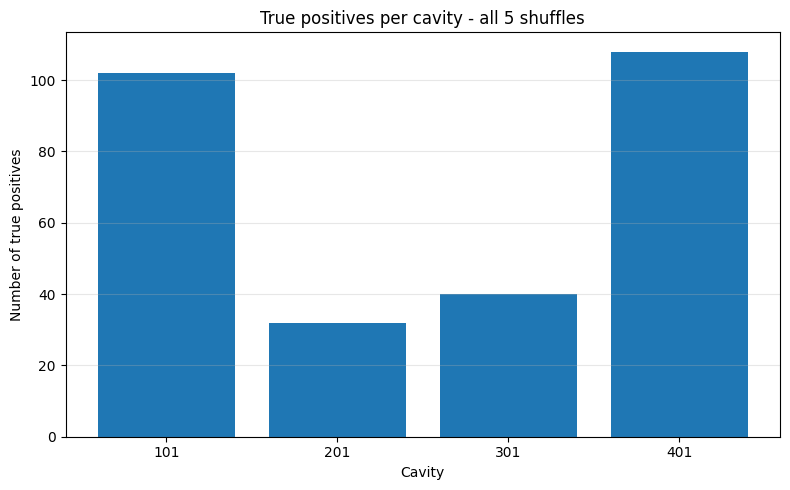

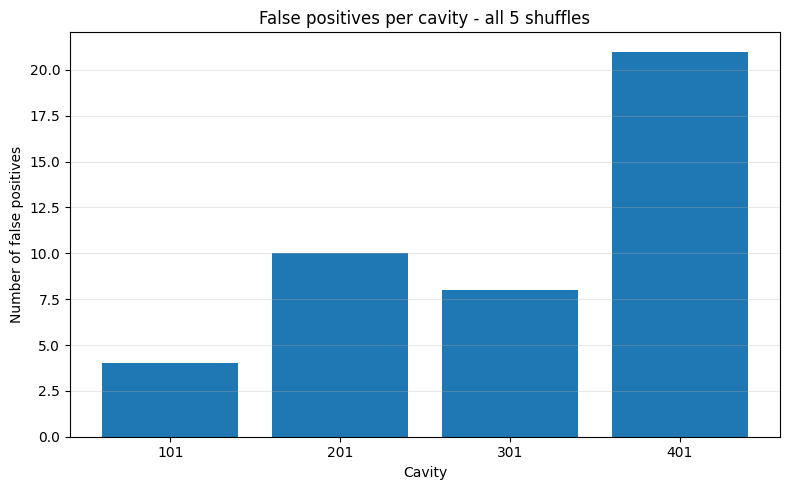

In [154]:
# ============================================================
# SAVE ALL PREDICTIONS
# ============================================================

all_test_predictions_df.to_csv("all_test_predictions.csv", index=False)
all_tp.to_csv("true_positives.csv", index=False)
all_fp.to_csv("false_positives.csv", index=False)


# ============================================================
# TP / FP COUNTS PER CAVITY
# ============================================================

tp_per_cavity = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "TP"
    ]
    .groupby("cavity")
    .size()
    .reset_index(name="TP")
)

fp_per_cavity = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "FP"
    ]
    .groupby("cavity")
    .size()
    .reset_index(name="FP")
)

display(tp_per_cavity)
display(fp_per_cavity)


# ============================================================
# SHORT CAVITY NAMES
# ============================================================

tp_per_cavity["cavity_short"] = tp_per_cavity["cavity"].str.extract(r"(\d{3})$")
fp_per_cavity["cavity_short"] = fp_per_cavity["cavity"].str.extract(r"(\d{3})$")


# ============================================================
# BAR PLOT: TRUE POSITIVES PER CAVITY
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    tp_per_cavity["cavity_short"],
    tp_per_cavity["TP"]
)

plt.xlabel("Cavity")
plt.ylabel("Number of true positives")
plt.title("True positives per cavity - all 5 shuffles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# BAR PLOT: FALSE POSITIVES PER CAVITY
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    fp_per_cavity["cavity_short"],
    fp_per_cavity["FP"]
)

plt.xlabel("Cavity")
plt.ylabel("Number of false positives")
plt.title("False positives per cavity - all 5 shuffles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [155]:
import pandas as pd
import matplotlib.pyplot as plt

all_test_predictions_df = pd.read_csv("all_test_predictions.csv")

In [156]:
tp_counts = (
    all_test_predictions_df[
        all_test_predictions_df["classification"] == "TP"
    ]
    .groupby(["seed", "cavity"])
    .size()
    .reset_index(name="TP")
)

tp_mean = (
    tp_counts
    .groupby("cavity")["TP"]
    .agg(["mean", "std"])
    .reset_index()
)

tp_mean["cavity_short"] = tp_mean["cavity"].str.extract(r"(\d{3})$")

display(tp_mean)

,cavity,mean,std,cavity_short
0,HBL-010RFC:RFS-DIG-101,20.4,1.516575,101
1,HBL-010RFC:RFS-DIG-201,6.4,2.792848,201
2,HBL-010RFC:RFS-DIG-301,8.0,3.082207,301
3,HBL-010RFC:RFS-DIG-401,21.6,2.509980,401


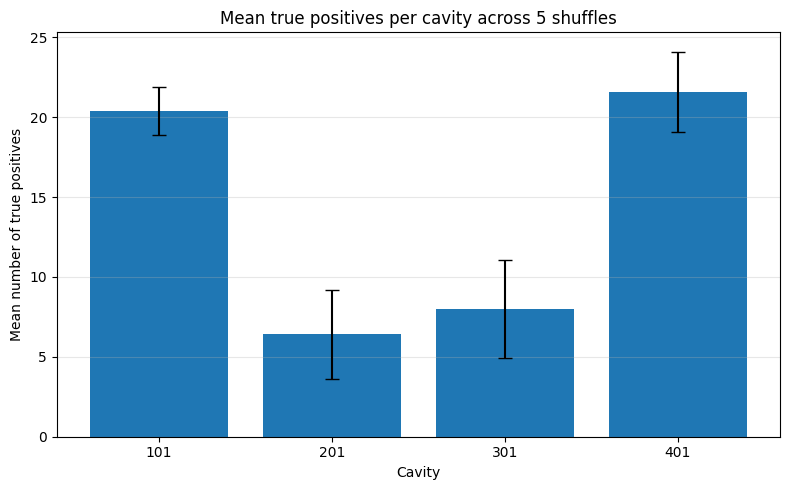

In [157]:
plt.figure(figsize=(8, 5))

plt.bar(
    tp_mean["cavity_short"],
    tp_mean["mean"],
    yerr=tp_mean["std"],
    capsize=5
)

plt.xlabel("Cavity")
plt.ylabel("Mean number of true positives")
plt.title("Mean true positives per cavity across 5 shuffles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [160]:
from pathlib import Path
import pandas as pd

files = {
    "field_amp":   "cavity_pulses_labeled_field_amp.parquet",
    "field_phase": "cavity_pulses_labeled_field_phase.parquet",
    "fwd_amp":     "cavity_pulses_labeled_fwd_amp.parquet",
    "fwd_phase":   "cavity_pulses_labeled_fwd_phase.parquet",
    "refl_amp":    "cavity_pulses_labeled_refl_amp.parquet",
    "refl_phase":  "cavity_pulses_labeled_refl_phase.parquet",
}

datasets = {}

for name, file in files.items():
    df = pd.read_parquet(file)
    datasets[name] = df

    print(
        name,
        "shape =", df.shape,
        "labels =", df["label"].value_counts().to_dict()
    )

field_amp shape = (40223, 66) labels = {0: 35414, 1: 4809}
field_phase shape = (40223, 66) labels = {0: 35414, 1: 4809}
fwd_amp shape = (40223, 66) labels = {0: 35414, 1: 4809}
fwd_phase shape = (40223, 66) labels = {0: 35414, 1: 4809}
refl_amp shape = (40223, 66) labels = {0: 35414, 1: 4809}
refl_phase shape = (40223, 66) labels = {0: 35414, 1: 4809}


field_amp shape = (40223, 66) labels = {0: 35414, 1: 4809}
field_phase shape = (40223, 66) labels = {0: 35414, 1: 4809}
fwd_amp shape = (40223, 66) labels = {0: 35414, 1: 4809}
fwd_phase shape = (40223, 66) labels = {0: 35414, 1: 4809}
refl_amp shape = (40223, 66) labels = {0: 35414, 1: 4809}
refl_phase shape = (40223, 66) labels = {0: 35414, 1: 4809}
field_amp aligned = True
field_phase aligned = True
fwd_amp aligned = True
fwd_phase aligned = True
refl_amp aligned = True
refl_phase aligned = True

Total DD: 1747
Total trips: 234

Usable DD: (1724, 90)
Usable trips: (172, 90)
AE input dimension: 90

SEED / SHUFFLE: 10
AE train: (1016, 90)
AE validation: (345, 90)
DD test pool: (345, 90)
Trip development: (86, 90)
Trip final test: (86, 90)
AE epochs: 500
Best AE validation loss: 0.02113666571676731
XGBoost feature count: 96
XGBoost input shape: (172, 96)
Best threshold: 0.32676767676767676
Validation F1: 0.8135593220338984

FINAL TEST
PR AUC: 0.809396692218781
Recall: 0.802325581395348

,seed,input_dim,xgb_features,ae_train,ae_val,trip_dev,trip_test,best_threshold,validation_f1,test_f1,precision,recall,roc_auc,pr_auc,ae_epochs,ae_best_val_loss
0,10,90,96,1016,345,86,86,0.326768,0.813559,0.711340,0.638889,0.802326,0.796309,0.809397,500,0.021137
1,20,90,96,1018,345,86,86,0.381212,0.736842,0.766667,0.734043,0.802326,0.825581,0.852708,500,0.032054
2,30,90,96,1017,345,86,86,0.044646,0.704225,0.719298,0.577465,0.953488,0.809627,0.838462,500,0.025375
3,40,90,96,1017,345,86,86,0.356465,0.852459,0.754098,0.711340,0.802326,0.827542,0.820890,500,0.022160
4,50,90,96,1016,345,86,86,0.292121,0.823529,0.745946,0.696970,0.802326,0.816522,0.851321,500,0.026086



MULTIVARIATE 6-PV — 5 SHUFFLES
pr_auc      : 0.8346 ± 0.0190
recall      : 0.8326 ± 0.0676
test_f1     : 0.7395 ± 0.0234
precision   : 0.6717 ± 0.0634
roc_auc     : 0.8151 ± 0.0127

TRUE POSITIVES


,seed,cavity,original_index,prob_trip
0,10,HBL-010RFC:RFS-DIG-101,1,0.990928
1,10,HBL-010RFC:RFS-DIG-101,20,0.995402
2,10,HBL-010RFC:RFS-DIG-101,32,0.995402
3,10,HBL-010RFC:RFS-DIG-101,36,0.995054
4,10,HBL-010RFC:RFS-DIG-101,47,0.995054
...,...,...,...,...
353,50,HBL-010RFC:RFS-DIG-401,184,0.904897
354,50,HBL-010RFC:RFS-DIG-401,191,0.650796
355,50,HBL-010RFC:RFS-DIG-401,208,0.485515
356,50,HBL-010RFC:RFS-DIG-401,215,0.721322



FALSE POSITIVES


,seed,cavity,original_index,prob_trip
0,10,HBL-010RFC:RFS-DIG-101,18,0.993702
1,10,HBL-010RFC:RFS-DIG-101,132,0.360733
2,10,HBL-010RFC:RFS-DIG-101,825,0.377443
3,10,HBL-010RFC:RFS-DIG-101,936,0.754270
4,10,HBL-010RFC:RFS-DIG-101,1074,0.329065
...,...,...,...,...
177,50,HBL-010RFC:RFS-DIG-401,972,0.720067
178,50,HBL-010RFC:RFS-DIG-401,1017,0.850514
179,50,HBL-010RFC:RFS-DIG-401,1184,0.770746
180,50,HBL-010RFC:RFS-DIG-401,1195,0.397314


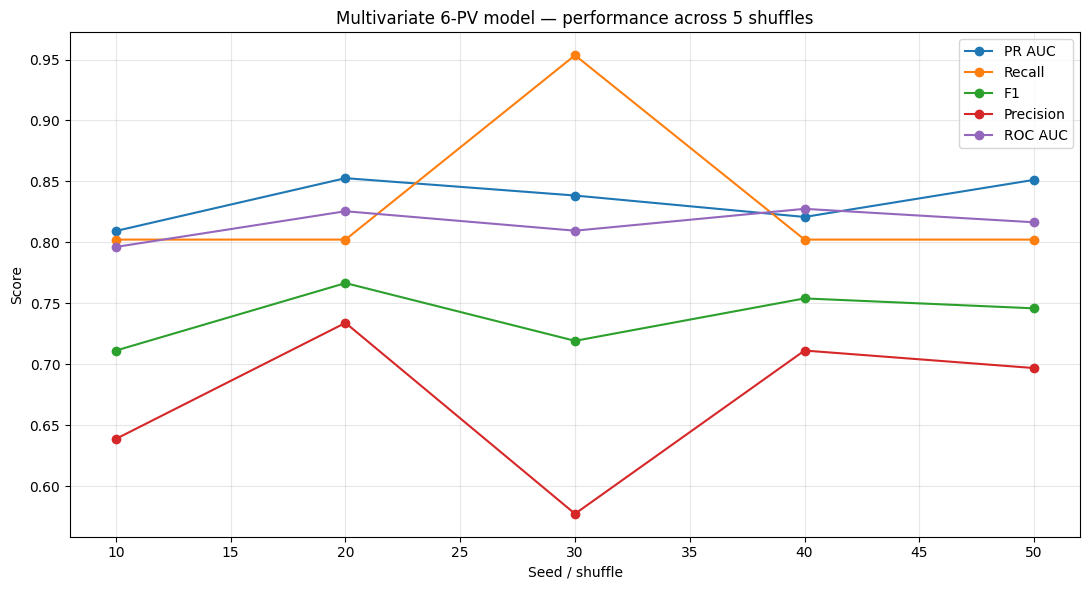

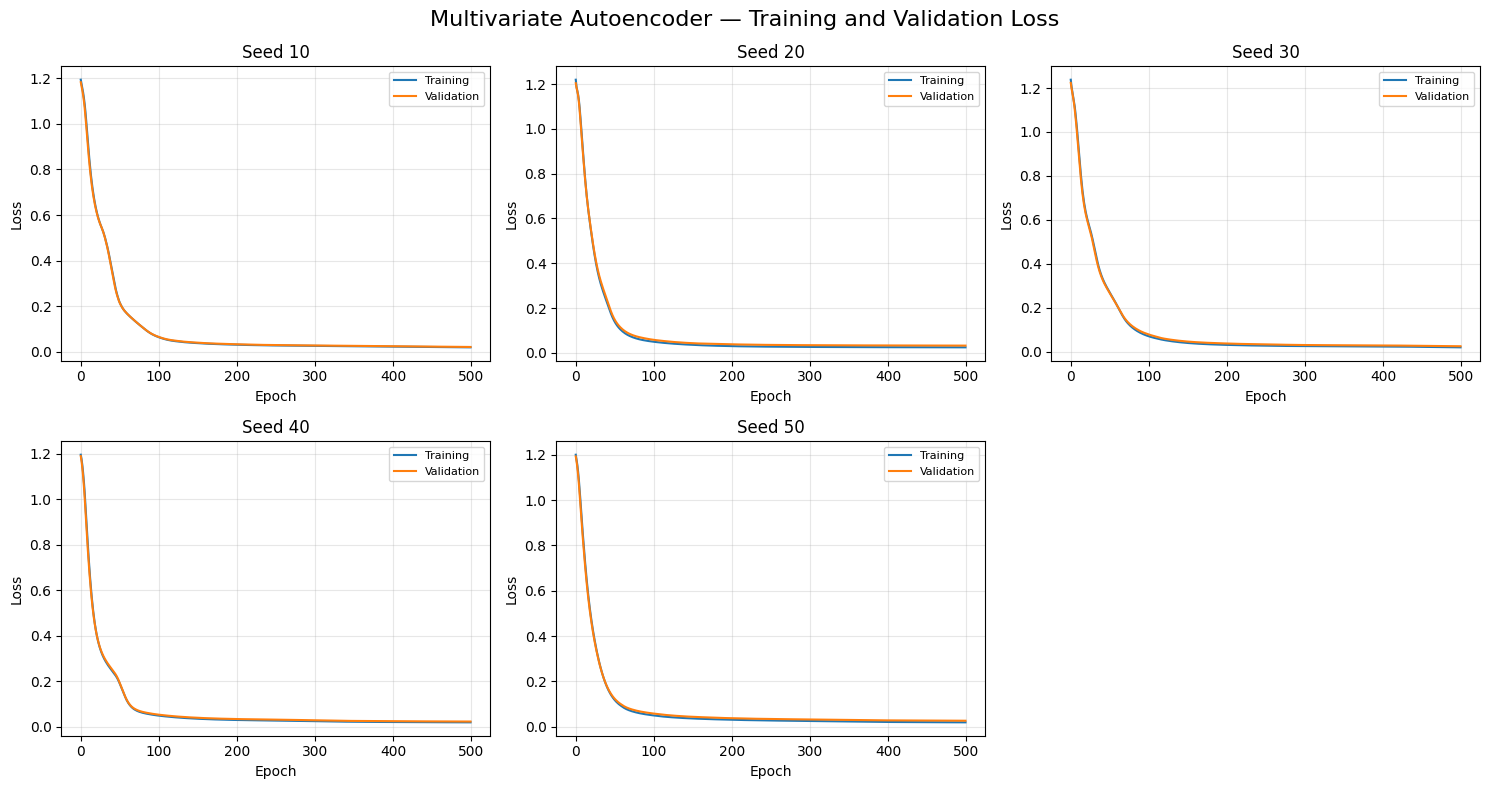

In [169]:
# ============================================================
# COMPLETE MULTIVARIATE MODEL
# 6 PV × 15 points = 90 AE inputs
# 90 RAW residuals + 6 residual statistics = 96 XGBoost inputs
# 4 cavities mixed + 5 shuffles
# ============================================================
import random, numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from pathlib import Path
from tensorflow.keras import backend as K, regularizers
from tensorflow.keras.layers import Input, Dense, LeakyReLU
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve, auc, confusion_matrix
from xgboost import XGBClassifier

# ============================================================
# LOAD DATA
# ============================================================

DATA_DIR = Path(".")
files = {
    "field_amp":"cavity_pulses_labeled_field_amp.parquet",
    "field_phase":"cavity_pulses_labeled_field_phase.parquet",
    "fwd_amp":"cavity_pulses_labeled_fwd_amp.parquet",
    "fwd_phase":"cavity_pulses_labeled_fwd_phase.parquet",
    "refl_amp":"cavity_pulses_labeled_refl_amp.parquet",
    "refl_phase":"cavity_pulses_labeled_refl_phase.parquet"
}

datasets = {name:pd.read_parquet(DATA_DIR/file) for name,file in files.items()}

for name,df in datasets.items():
    print(name, df.shape, df["label"].value_counts().to_dict())

reference = datasets["field_amp"][["cavity","label"]].reset_index(drop=True)
for name,df in datasets.items():
    print(name, "aligned =", reference.equals(df[["cavity","label"]].reset_index(drop=True)))

# ============================================================
# SETTINGS
# ============================================================

VARIABLES = ["field_amp","field_phase","fwd_amp","fwd_phase","refl_amp","refl_phase"]

cavity_names = [
    "HBL-010RFC:RFS-DIG-101",
    "HBL-010RFC:RFS-DIG-201",
    "HBL-010RFC:RFS-DIG-301",
    "HBL-010RFC:RFS-DIG-401"
]

FIXED_LEN = 15
WINDOW_SIZE = 6
EPOCHS = 500
BATCH_SIZE = 16
PATIENCE = 20
SEEDS = [10,20,30,40,50]

dataset_ref = datasets["field_amp"]
value_columns = [c for c in dataset_ref.columns if c.startswith("value_")]

# ============================================================
# DD / TRIP
# ============================================================

dd_all = dataset_ref[
    (dataset_ref["label"]==0) &
    (dataset_ref["cavity"].isin(cavity_names))
].copy()

trip_all = dataset_ref[
    (dataset_ref["label"]==1) &
    (dataset_ref["cavity"].isin(cavity_names))
].copy()

dd_all["_global_index"] = dd_all.index
trip_all["_global_index"] = trip_all.index

dd_all = dd_all.reset_index(drop=True)
trip_all = trip_all.reset_index(drop=True)

print("Total DD:",len(dd_all))
print("Total trips:",len(trip_all))

# ============================================================
# FUNCTIONS
# ============================================================

def get_flat_plateau(y,slope_threshold=0.1,amp_min=18,amp_max=24):
    y=np.asarray(y,float)
    slope=np.diff(y)
    mask=np.zeros(len(y),bool)
    mask[1:]=np.abs(slope)<=slope_threshold
    mask&=(y>=amp_min)&(y<=amp_max)

    segments=[]
    start=None

    for i,flag in enumerate(mask):
        if flag and start is None:
            start=i
        elif not flag and start is not None:
            segments.append((start,i))
            start=None

    if start is not None:
        segments.append((start,len(y)))

    return None if not segments else max(segments,key=lambda s:s[1]-s[0])


def resample_plateau(flat,fixed_len):
    flat=np.asarray(flat,float)
    return np.interp(
        np.linspace(0,1,fixed_len),
        np.linspace(0,1,len(flat)),
        flat
    )


def get_reference_plateau(global_index):
    y=datasets["field_amp"].iloc[global_index][value_columns].to_numpy(float)

    plateau=get_flat_plateau(
        y,
        slope_threshold=0.1,
        amp_min=18,
        amp_max=24
    )

    if plateau is None:
        return None

    start,end=plateau
    return None if end-start<6 else (start,end)


def extract_multivariate_plateau(global_index,fixed_len=FIXED_LEN):
    plateau=get_reference_plateau(global_index)

    if plateau is None:
        return None

    start,end=plateau
    vector=[]

    for variable in VARIABLES:
        y=datasets[variable].iloc[global_index][value_columns].to_numpy(float)
        flat=y[start:end]

        if len(flat)<6 or not np.isfinite(flat).all():
            return None

        vector.extend(resample_plateau(flat,fixed_len))

    return np.asarray(vector,float)


def mean_window_range_global(global_index):
    plateau=get_reference_plateau(global_index)

    if plateau is None:
        return np.nan

    start,end=plateau
    y=datasets["field_amp"].iloc[global_index][value_columns].to_numpy(float)
    flat=y[start:end]

    ranges=[
        flat[j:j+WINDOW_SIZE].max()-flat[j:j+WINDOW_SIZE].min()
        for j in range(0,len(flat)-WINDOW_SIZE+1,WINDOW_SIZE)
    ]

    return np.mean(ranges) if ranges else np.nan


def remove_training_dd_outliers(df):
    df=df.copy()

    df["mean_window_range"]=[
        mean_window_range_global(int(i))
        for i in df["_global_index"]
    ]

    cleaned=[]

    for cavity in df["cavity"].unique():
        temp=df[df["cavity"]==cavity].copy()
        values=temp["mean_window_range"].dropna()

        if len(values)==0:
            continue

        q1,q3=values.quantile(.25),values.quantile(.75)
        upper=q3+1.5*(q3-q1)

        cleaned.append(
            temp[temp["mean_window_range"]<=upper]
        )

    return pd.concat(cleaned,ignore_index=True)


def build_autoencoder(input_dim):
    inp=Input(shape=(input_dim,))
    x=Dense(8,activation="relu",kernel_regularizer=regularizers.l2(.01))(inp)
    x=Dense(4)(x)
    x=LeakyReLU(negative_slope=.075)(x)
    x=Dense(8,activation="relu",kernel_regularizer=regularizers.l2(.01))(x)
    out=Dense(input_dim)(x)

    model=Model(inp,out)
    model.compile(
        loss="mean_squared_error",
        optimizer=Adam(learning_rate=1e-4)
    )
    return model


def residual_features(residual):
    residual=np.asarray(residual)

    features=pd.DataFrame(
        residual,
        columns=[f"res_raw_{i+1}" for i in range(residual.shape[1])]
    )

    features["res_mean"]=residual.mean(axis=1)
    features["res_std"]=residual.std(axis=1)
    features["res_max_minus_min"]=residual.max(axis=1)-residual.min(axis=1)
    features["res_mae"]=np.mean(np.abs(residual),axis=1)
    features["res_mse"]=np.mean(residual**2,axis=1)
    features["res_max_abs"]=np.max(np.abs(residual),axis=1)

    return features


def sample_matching_dd_indices(metadata,trip_meta,random_state):
    selected=[]
    rng=np.random.RandomState(random_state)

    for cavity_name,n_needed in trip_meta["cavity"].value_counts().items():
        available=metadata[metadata["cavity"]==cavity_name].index.to_numpy()

        if len(available)<n_needed:
            raise ValueError(f"{cavity_name}: need {n_needed} DD, have {len(available)}")

        selected.extend(
            rng.choice(
                available,
                size=n_needed,
                replace=False
            ).tolist()
        )

    return np.array(selected,int)

# ============================================================
# PRE-EXTRACT DD / TRIPS
# ============================================================

dd_vectors=[]
dd_metadata=[]

for idx,row in dd_all.iterrows():
    g=int(row["_global_index"])
    x=extract_multivariate_plateau(g)

    if x is not None:
        dd_vectors.append(x)
        dd_metadata.append({
            "original_index":idx,
            "global_index":g,
            "cavity":row["cavity"]
        })

X_dd_all=np.vstack(dd_vectors)
dd_metadata=pd.DataFrame(dd_metadata)

trip_vectors=[]
trip_metadata=[]

for idx,row in trip_all.iterrows():
    g=int(row["_global_index"])
    x=extract_multivariate_plateau(g)

    if x is not None:
        trip_vectors.append(x)
        trip_metadata.append({
            "original_index":idx,
            "global_index":g,
            "cavity":row["cavity"]
        })

X_trip_all=np.vstack(trip_vectors)
trip_metadata=pd.DataFrame(trip_metadata)

print("Usable DD:",X_dd_all.shape)
print("Usable trips:",X_trip_all.shape)
print("AE input dimension:",X_dd_all.shape[1])

# ============================================================
# 5 SHUFFLES
# ============================================================

all_results=[]
all_histories=[]
all_test_predictions=[]

for seed in SEEDS:

    print("\n"+"="*70)
    print("SEED:",seed)
    print("="*70)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # DD 60/20/20
    dd_idx=np.arange(len(X_dd_all))

    idx_dd_train,idx_dd_temp=train_test_split(
        dd_idx,
        test_size=.40,
        random_state=seed,
        stratify=dd_metadata["cavity"]
    )

    idx_dd_val,idx_dd_test=train_test_split(
        idx_dd_temp,
        test_size=.50,
        random_state=seed,
        stratify=dd_metadata.iloc[idx_dd_temp]["cavity"]
    )

    # Clean AE train
    train_orig=dd_metadata.iloc[idx_dd_train]["original_index"].to_numpy()
    dd_train_df=dd_all.iloc[train_orig].copy()
    dd_train_clean=remove_training_dd_outliers(dd_train_df)

    clean_global_indices=dd_train_clean["_global_index"].astype(int).to_numpy()

    X_train=np.vstack([
        extract_multivariate_plateau(i)
        for i in clean_global_indices
    ])

    X_val=X_dd_all[idx_dd_val]
    X_test_dd=X_dd_all[idx_dd_test]

    meta_val=dd_metadata.iloc[idx_dd_val].reset_index(drop=True)
    meta_test=dd_metadata.iloc[idx_dd_test].reset_index(drop=True)

    # Trips 50/50
    trip_idx=np.arange(len(X_trip_all))

    idx_trip_dev,idx_trip_test=train_test_split(
        trip_idx,
        test_size=.50,
        random_state=seed,
        stratify=trip_metadata["cavity"]
    )

    X_trip_dev=X_trip_all[idx_trip_dev]
    X_trip_test=X_trip_all[idx_trip_test]

    trip_meta_dev=trip_metadata.iloc[idx_trip_dev].reset_index(drop=True)
    trip_meta_test=trip_metadata.iloc[idx_trip_test].reset_index(drop=True)

    print("AE train:",X_train.shape)
    print("AE validation:",X_val.shape)
    print("Trip development:",X_trip_dev.shape)
    print("Trip final test:",X_trip_test.shape)

    # Standardize
    scaler=StandardScaler()

    X_train_scaled=scaler.fit_transform(X_train)
    X_val_scaled=scaler.transform(X_val)
    X_test_dd_scaled=scaler.transform(X_test_dd)
    X_trip_dev_scaled=scaler.transform(X_trip_dev)
    X_trip_test_scaled=scaler.transform(X_trip_test)

    # AE
    K.clear_session()

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    ae=build_autoencoder(X_train_scaled.shape[1])

    history=ae.fit(
        X_train_scaled,
        X_train_scaled,
        validation_data=(X_val_scaled,X_val_scaled),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=PATIENCE,
                restore_best_weights=True
            )
        ]
    )

    all_histories.append({
        "seed":seed,
        "history":history.history
    })

    # Reconstruction / residuals
    rec_dd_val=ae.predict(X_val_scaled,verbose=0)
    rec_dd_test=ae.predict(X_test_dd_scaled,verbose=0)
    rec_trip_dev=ae.predict(X_trip_dev_scaled,verbose=0)
    rec_trip_test=ae.predict(X_trip_test_scaled,verbose=0)

    feat_dd_val=residual_features(X_val_scaled-rec_dd_val)
    feat_dd_test=residual_features(X_test_dd_scaled-rec_dd_test)
    feat_trip_dev=residual_features(X_trip_dev_scaled-rec_trip_dev)
    feat_trip_test=residual_features(X_trip_test_scaled-rec_trip_test)

    print("XGBoost feature count:",feat_dd_val.shape[1])

    # Balance by cavity
    idx_dd_dev_bal=sample_matching_dd_indices(
        meta_val,
        trip_meta_dev,
        seed
    )

    idx_dd_test_bal=sample_matching_dd_indices(
        meta_test,
        trip_meta_test,
        seed+100
    )

    feat_dd_dev_bal=feat_dd_val.iloc[idx_dd_dev_bal].reset_index(drop=True)
    feat_dd_test_bal=feat_dd_test.iloc[idx_dd_test_bal].reset_index(drop=True)
    meta_dd_test_bal=meta_test.iloc[idx_dd_test_bal].reset_index(drop=True)

    # Classifier pool
    dd_clf=feat_dd_dev_bal.copy()
    dd_clf["label"]=0

    trip_clf=feat_trip_dev.copy()
    trip_clf["label"]=1

    classifier_pool=pd.concat(
        [dd_clf,trip_clf],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    FEATURE_COLUMNS=[
        c for c in classifier_pool.columns
        if c!="label"
    ]

    X_clf=classifier_pool[FEATURE_COLUMNS]
    y_clf=classifier_pool["label"]

    # XGBoost train / threshold val
    X_xgb_train,X_threshold_val,y_xgb_train,y_threshold_val=train_test_split(
        X_clf,
        y_clf,
        test_size=.30,
        random_state=seed,
        stratify=y_clf
    )

    xgb=XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=.05,
        subsample=.8,
        colsample_bytree=.8,
        eval_metric="logloss",
        random_state=seed,
        n_jobs=-1
    )

    xgb.fit(X_xgb_train,y_xgb_train)

    # Threshold
    val_prob=xgb.predict_proba(X_threshold_val)[:,1]

    thresholds=np.linspace(.01,.99,199)

    f1_scores=[
        f1_score(
            y_threshold_val,
            (val_prob>=t).astype(int)
        )
        for t in thresholds
    ]

    best_idx=np.argmax(f1_scores)
    best_threshold=thresholds[best_idx]
    validation_f1=f1_scores[best_idx]

    # Final test
    dd_final=feat_dd_test_bal.copy()
    dd_final["label"]=0
    dd_final["cavity"]=meta_dd_test_bal["cavity"].to_numpy()
    dd_final["original_index"]=meta_dd_test_bal["original_index"].to_numpy()
    dd_final["source"]="DD"

    trip_final=feat_trip_test.copy()
    trip_final["label"]=1
    trip_final["cavity"]=trip_meta_test["cavity"].to_numpy()
    trip_final["original_index"]=trip_meta_test["original_index"].to_numpy()
    trip_final["source"]="Trip"

    final_test=pd.concat(
        [dd_final,trip_final],
        ignore_index=True
    ).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

    X_final=final_test[FEATURE_COLUMNS]
    y_final=final_test["label"]

    test_prob=xgb.predict_proba(X_final)[:,1]
    y_pred=(test_prob>=best_threshold).astype(int)

    final_test["prob_trip"]=test_prob
    final_test["predicted_label"]=y_pred
    final_test["seed"]=seed

    final_test["classification"]=np.select(
        [
            (final_test["label"]==1)&(final_test["predicted_label"]==1),
            (final_test["label"]==0)&(final_test["predicted_label"]==1),
            (final_test["label"]==0)&(final_test["predicted_label"]==0),
            (final_test["label"]==1)&(final_test["predicted_label"]==0)
        ],
        ["TP","FP","TN","FN"],
        default="Unknown"
    )

    all_test_predictions.append(final_test.copy())

    # Metrics
    test_f1=f1_score(y_final,y_pred)
    precision=precision_score(y_final,y_pred,zero_division=0)
    recall=recall_score(y_final,y_pred,zero_division=0)
    roc_auc=roc_auc_score(y_final,test_prob)

    precision_curve,recall_curve,_=precision_recall_curve(
        y_final,
        test_prob
    )

    pr_auc=auc(
        recall_curve,
        precision_curve
    )

    cm=confusion_matrix(
        y_final,
        y_pred
    )

    print(
        f"PR AUC={pr_auc:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={test_f1:.3f} | "
        f"Precision={precision:.3f} | "
        f"ROC AUC={roc_auc:.3f}"
    )

    print(cm)

    all_results.append({
        "seed":seed,
        "input_dim":X_train.shape[1],
        "xgb_features":len(FEATURE_COLUMNS),
        "ae_train":len(X_train),
        "ae_val":len(X_val),
        "trip_dev":len(X_trip_dev),
        "trip_test":len(X_trip_test),
        "best_threshold":best_threshold,
        "validation_f1":validation_f1,
        "test_f1":test_f1,
        "precision":precision,
        "recall":recall,
        "roc_auc":roc_auc,
        "pr_auc":pr_auc,
        "ae_epochs":len(history.history["loss"]),
        "ae_best_val_loss":min(history.history["val_loss"])
    })

# ============================================================
# RESULTS
# ============================================================

results_multivariate=pd.DataFrame(all_results)
display(results_multivariate)

metrics=["pr_auc","recall","test_f1","precision","roc_auc"]

print("\nMULTIVARIATE 6-PV — 5 SHUFFLES")

for metric in metrics:
    print(
        f"{metric:12s}: "
        f"{results_multivariate[metric].mean():.4f} ± "
        f"{results_multivariate[metric].std():.4f}"
    )

# ============================================================
# TP / FP
# ============================================================

all_test_predictions_df=pd.concat(
    all_test_predictions,
    ignore_index=True
)

all_tp=(
    all_test_predictions_df[
        all_test_predictions_df["classification"]=="TP"
    ][["seed","cavity","original_index","prob_trip"]]
    .sort_values(["seed","cavity","original_index"])
    .reset_index(drop=True)
)

all_fp=(
    all_test_predictions_df[
        all_test_predictions_df["classification"]=="FP"
    ][["seed","cavity","original_index","prob_trip"]]
    .sort_values(["seed","cavity","original_index"])
    .reset_index(drop=True)
)

display(all_tp)
display(all_fp)

# ============================================================
# SAVE
# ============================================================

results_multivariate.to_csv(
    "multivariate_6PV_raw_residual_results.csv",
    index=False
)

all_test_predictions_df.to_csv(
    "multivariate_6PV_raw_residual_predictions.csv",
    index=False
)

all_tp.to_csv(
    "multivariate_6PV_raw_residual_TP.csv",
    index=False
)

all_fp.to_csv(
    "multivariate_6PV_raw_residual_FP.csv",
    index=False
)

# ============================================================
# PERFORMANCE
# ============================================================

plt.figure(figsize=(11,6))

for metric,label in [
    ("pr_auc","PR AUC"),
    ("recall","Recall"),
    ("test_f1","F1"),
    ("precision","Precision"),
    ("roc_auc","ROC AUC")
]:
    plt.plot(
        results_multivariate["seed"],
        results_multivariate[metric],
        marker="o",
        label=label
    )

plt.xlabel("Seed / shuffle")
plt.ylabel("Score")
plt.title("Multivariate 6-PV Model — Performance Across 5 Shuffles")
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

# ============================================================
# TRAIN + VALIDATION LOSS — 3 TOP, 2 BOTTOM
# ============================================================

fig,axes=plt.subplots(
    2,
    3,
    figsize=(15,8)
)

axes=axes.flatten()

for ax,item in zip(axes,all_histories):
    seed=item["seed"]
    history=item["history"]

    ax.plot(history["loss"],label="Training")
    ax.plot(history["val_loss"],label="Validation")

    ax.set_title(f"Seed {seed}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=.3)
    ax.legend(fontsize=8)

axes[-1].axis("off")

fig.suptitle(
    "Multivariate Autoencoder — Training and Validation Loss",
    fontsize=16
)

plt.tight_layout()
plt.show()